In [67]:
import pandas as pd # manejo de tablas
from pathlib import Path # rutas de archivos y carpetas de forma
import cv2 # procesamiento de imágenes
import matplotlib.pyplot as plt # mostrar imágenes y gráficos 
import numpy as np # operaciones con matrices.
from skimage.segmentation import morphological_chan_vese


## Carga y visualización inicial de las imágenes

Se utilizan las 2000 imágenes dermatoscópicas de entrenamiento de
ISIC 2017. Los diagnósticos se obtienen del archivo CSV y se vinculan
con las fotografías mediante el identificador `image_id`.

El conjunto incluye 1372 imágenes de nevus, 374 de melanoma y 254 de
queratosis seborreica. Se verificó que las 2000 fotografías están
disponibles en `Data` y tienen una correspondencia en el CSV.

Se visualiza una imagen de cada diagnóstico para inspeccionar sus
características y detectar elementos que puedan afectar el procesamiento.
Las imágenes se convierten de BGR a RGB para representar correctamente
sus colores.

En esta etapa se conserva la resolución original y no se aplican filtros.
Las máscaras de referencia se mantienen separadas de las fotografías.

In [3]:
carpeta_data = Path("Data")

df = pd.read_csv(
    carpeta_data / "ISIC-2017_Training_Part3_GroundTruth.csv"
)

# Verificar que las etiquetas sean válidas
etiquetas = df[["melanoma", "seborrheic_keratosis"]]

if not etiquetas.isin([0, 1]).all().all():
    raise ValueError("Hay etiquetas vacías o diferentes de 0 y 1.")

if (etiquetas.sum(axis=1) > 1).any():
    raise ValueError("Hay imágenes con ambos diagnósticos positivos.")

df["diagnostico"] = np.select(
    [
        df["melanoma"] == 1,
        df["seborrheic_keratosis"] == 1,
    ],
    ["Melanoma", "Queratosis seborreica"],
    default="Nevus"
)

display(df.head())
display(df["diagnostico"].value_counts())

,image_id,melanoma,seborrheic_keratosis,diagnostico
0,ISIC_0000000,0.0,0.0,Nevus
1,ISIC_0000001,0.0,0.0,Nevus
2,ISIC_0000002,1.0,0.0,Melanoma
3,ISIC_0000003,0.0,0.0,Nevus
4,ISIC_0000004,1.0,0.0,Melanoma


diagnostico
Nevus                    1372
Melanoma                  374
Queratosis seborreica     254
Name: count, dtype: int64

In [4]:
# IDs de las fotografías disponibles en Data y sus subcarpetas
ids_disponibles = {
    ruta.stem
    for ruta in carpeta_data.rglob("*")
    if ruta.is_file() and ruta.suffix.lower() in {".jpg", ".jpeg"}
}

# Seleccionar sus registros en los metadatos
df_data = df[df["image_id"].isin(ids_disponibles)].copy()

recuento = (
    df_data.drop_duplicates("image_id")["diagnostico"]
    .value_counts()
    .rename_axis("Diagnóstico")
    .reset_index(name="Cantidad de imágenes")
)

display(recuento)
print(f"Total con diagnóstico: {recuento['Cantidad de imágenes'].sum()}")

sin_diagnostico = ids_disponibles - set(df["image_id"])
print(f"Fotos sin coincidencia en el CSV: {len(sin_diagnostico)}")

,Diagnóstico,Cantidad de imágenes
0,Nevus,1372
1,Melanoma,374
2,Queratosis seborreica,254


Total con diagnóstico: 2000
Fotos sin coincidencia en el CSV: 0


### Observaciones iniciales

La inspección de los ejemplos seleccionados permite evaluar diferencias
de color, contraste, delimitación y apariencia superficial, así como
identificar posibles pelos, marcas o reflejos.

Estos elementos pueden interferir en la segmentación y modificar las
mediciones de color y textura. Por ello, se evaluarán técnicas de
preprocesamiento procurando preservar las características de las lesiones.

Las observaciones realizadas sobre estos ejemplos no se consideran
características generales de cada diagnóstico.

## Caracterización técnica del conjunto de imágenes

Se recorren las fotografías disponibles en `Data` y se vincula cada una
con su diagnóstico mediante el identificador `image_id`.

Se registran formato, dimensiones, cantidad de canales, tipo de dato,
bits por canal de la matriz cargada y valores mínimo y máximo de intensidad.
Las máscaras PNG y los archivos auxiliares no se incluyen en este análisis.

El objetivo es identificar diferencias técnicas que puedan influir en
el procesamiento. Las diferencias de dimensiones no implican por sí
solas que sea necesario redimensionar las imágenes; cualquier ajuste
posterior deberá justificarse considerando su efecto sobre la forma
y la textura.

In [5]:
# Carpeta con fotografías y superpíxeles
carpeta_imagenes = Path("Data/ISIC-2017_Training_Data")

# Seleccionar solo fotografías JPG, sin incluir los superpíxeles PNG
rutas = {
    ruta.stem: ruta
    for ruta in carpeta_imagenes.iterdir()
    if ruta.is_file() and ruta.suffix.lower() in {".jpg", ".jpeg"}
}

filas = []

# Vincular cada fotografía con el diagnóstico del CSV
for _, registro in df.iterrows():
    image_id = registro["image_id"]
    ruta = rutas[image_id]

    # Leer sin modificar canales ni profundidad
    imagen = cv2.imread(str(ruta), cv2.IMREAD_UNCHANGED)

    if imagen is None:
        raise ValueError(f"No se pudo leer: {ruta}")

    alto, ancho = imagen.shape[:2]
    canales = 1 if imagen.ndim == 2 else imagen.shape[2]

    filas.append({
        "image_id": image_id,
        "Diagnóstico": registro["diagnostico"],
        "Archivo": ruta.name,
        "Formato": ruta.suffix.lower(),
        "Ancho (px)": ancho,
        "Alto (px)": alto,
        "Canales": canales,
        "Tipo de dato": str(imagen.dtype),
        "Bits por canal": imagen.dtype.itemsize * 8,
        "Mínimo": int(imagen.min()),
        "Máximo": int(imagen.max()),
    })

# Tabla con las propiedades de cada imagen
caracteristicas = pd.DataFrame(filas)

print(f"Total de imágenes: {len(caracteristicas)}")
display(caracteristicas.head())

# Resumen por diagnóstico
resumen = caracteristicas.groupby("Diagnóstico").agg(
    Cantidad=("Archivo", "count"),
    Ancho_mínimo=("Ancho (px)", "min"),
    Ancho_máximo=("Ancho (px)", "max"),
    Alto_mínimo=("Alto (px)", "min"),
    Alto_máximo=("Alto (px)", "max"),
    Canales=("Canales", lambda x: sorted(x.unique())),
    Tipo_de_dato=("Tipo de dato", lambda x: sorted(x.unique())),
    Bits_por_canal=("Bits por canal", lambda x: sorted(x.unique())),
    Formato=("Formato", lambda x: sorted(x.unique())),
    Intensidad_mínima=("Mínimo", "min"),
    Intensidad_máxima=("Máximo", "max"),
)

display(resumen)

Total de imágenes: 2000


,image_id,Diagnóstico,Archivo,Formato,Ancho (px),Alto (px),Canales,Tipo de dato,Bits por canal,Mínimo,Máximo
0,ISIC_0000000,Nevus,ISIC_0000000.jpg,.jpg,1022,767,3,uint8,8,16,255
1,ISIC_0000001,Nevus,ISIC_0000001.jpg,.jpg,1022,767,3,uint8,8,5,255
2,ISIC_0000002,Melanoma,ISIC_0000002.jpg,.jpg,1022,767,3,uint8,8,0,255
3,ISIC_0000003,Nevus,ISIC_0000003.jpg,.jpg,1022,767,3,uint8,8,15,255
4,ISIC_0000004,Melanoma,ISIC_0000004.jpg,.jpg,1022,767,3,uint8,8,0,255


,Cantidad,Ancho_mínimo,Ancho_máximo,Alto_mínimo,Alto_máximo,Canales,Tipo_de_dato,Bits_por_canal,Formato,Intensidad_mínima,Intensidad_máxima
Diagnóstico,,,,,,,,,,,
Melanoma,374,679,6708,540,4459,[3],[uint8],[8],[.jpg],0,255
Nevus,1372,576,6748,542,4499,[3],[uint8],[8],[.jpg],0,255
Queratosis seborreica,254,1007,6708,704,4461,[3],[uint8],[8],[.jpg],0,255


### Resultado de la caracterización técnica

Se caracterizaron las 2000 fotografías del conjunto: 1372 de nevus,
374 de melanoma y 254 de queratosis seborreica. Para cada imagen se
registraron formato, dimensiones, cantidad de canales, tipo de dato,
bits por canal y rango de intensidades.

La tabla resumen permite identificar diferencias técnicas entre las
imágenes que deben considerarse al definir los parámetros de procesamiento.

Para las etapas posteriores se seleccionará una muestra aleatoria
equilibrada de 50 imágenes por diagnóstico, con 150 imágenes en total
y una semilla fija para garantizar la reproducibilidad.

In [6]:
# Seleccionar 50 imágenes por diagnóstico
df_muestra = (
    df.groupby("diagnostico", group_keys=False)
    .sample(n=50, random_state=42)
    .reset_index(drop=True)
)

display(df_muestra["diagnostico"].value_counts())
print(f"Total seleccionado: {len(df_muestra)}")

diagnostico
Melanoma                 50
Nevus                    50
Queratosis seborreica    50
Name: count, dtype: int64

Total seleccionado: 150


## Análisis de los canales RGB de la muestra

Se calcula la intensidad media de los canales R, G y B para cada una
de las 150 imágenes seleccionadas. Los resultados se agrupan por
diagnóstico y se representan mediante diagramas de caja, que permiten
comparar la mediana y la dispersión de los valores entre imágenes.

Cada observación corresponde a la media de un canal en una fotografía.
El cálculo se realiza sobre la imagen completa, por lo que incluye
la lesión, la piel circundante y los posibles artefactos. Las diferencias
observadas también pueden estar influidas por las condiciones de adquisición.

R                      G                      B  \
                         mean    std  median    mean    std  median    mean   
Diagnóstico                                                                   
Melanoma               176.16  30.90  178.12  144.93  24.90  148.20  133.21   
Nevus                  185.67  30.62  186.73  157.45  31.96  152.54  142.73   
Queratosis seborreica  176.99  23.12  177.31  146.21  24.51  149.42  136.28   

                                      
                         std  median  
Diagnóstico                           
Melanoma               24.30  132.40  
Nevus                  32.72  137.66  
Queratosis seborreica  27.10  136.11

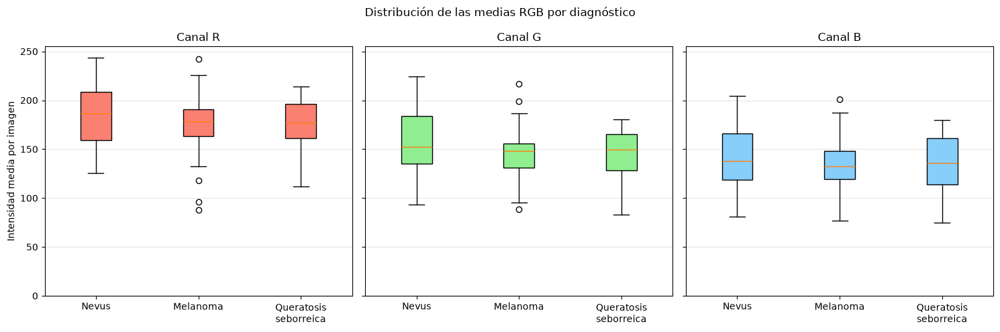

In [7]:
filas_rgb = []

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer: {rutas[image_id]}")

    rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Promedio de todos los píxeles, separado por canal
    medias = rgb.mean(axis=(0, 1))

    filas_rgb.append({
        "image_id": image_id,
        "Diagnóstico": registro["diagnostico"],
        "R": medias[0],
        "G": medias[1],
        "B": medias[2],
    })

rgb_medias = pd.DataFrame(filas_rgb)

# Resumen de las medias por imagen, agrupadas por diagnóstico
resumen_rgb = (
    rgb_medias.groupby("Diagnóstico")[["R", "G", "B"]]
    .agg(["mean", "std", "median"])
    .round(2)
)

display(resumen_rgb)

# Un diagrama de caja por canal
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]
colores = {"R": "salmon", "G": "lightgreen", "B": "lightskyblue"}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, canal in zip(axes, ["R", "G", "B"]):
    valores = [
        rgb_medias.loc[rgb_medias["Diagnóstico"] == d, canal]
        for d in diagnosticos
    ]

    cajas = ax.boxplot(valores, patch_artist=True)

    for caja in cajas["boxes"]:
        caja.set_facecolor(colores[canal])

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(
        ["Nevus", "Melanoma", "Queratosis\nseborreica"]
    )
    ax.set_title(f"Canal {canal}")
    ax.set_ylim(0, 255)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Intensidad media por imagen")
fig.suptitle("Distribución de las medias RGB por diagnóstico")

plt.tight_layout()
plt.show()

### Histogramas promedio por diagnóstico

Se calculan los histogramas RGB, HSV y de escala de grises de cada imagen.
Cada histograma se normaliza por su cantidad de píxeles y luego se
promedia entre las 50 imágenes de cada diagnóstico, otorgando igual
peso a cada fotografía.

El análisis se realiza sobre las imágenes completas. En HSV, H tiene
un rango de 0 a 179, mientras que S y V van de 0 a 255; sus valores
representan magnitudes distintas y no deben interpretarse como equivalentes.

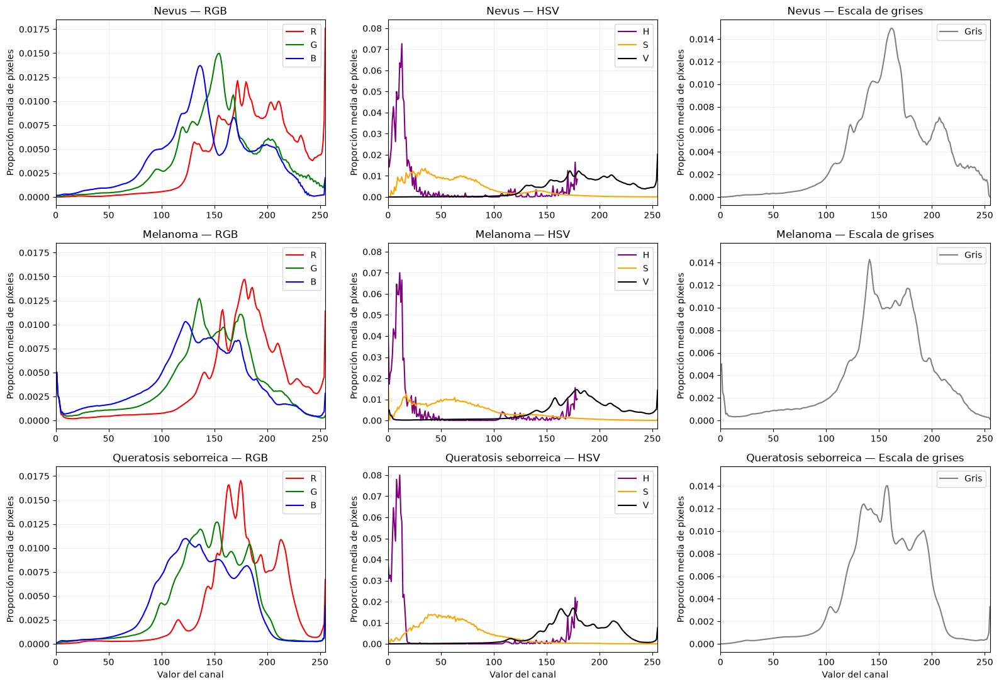

In [8]:
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]

# Guardar histogramas individuales por diagnóstico y canal
canales = ["R", "G", "B", "H", "S", "V", "Gris"]

histogramas = {
    diagnostico: {canal: [] for canal in canales}
    for diagnostico in diagnosticos
}

for _, registro in df_muestra.iterrows():
    imagen = cv2.imread(str(rutas[registro["image_id"]]))

    if imagen is None:
        raise ValueError(f"No se pudo leer: {registro['image_id']}")

    rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    gris = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    grupo = histogramas[registro["diagnostico"]]

    for i, canal in enumerate("RGB"):
        hist = cv2.calcHist([rgb], [i], None, [256], [0, 256])
        grupo[canal].append(hist.ravel() / hist.sum())

    for i, (canal, niveles) in enumerate(
        zip(["H", "S", "V"], [180, 256, 256])
    ):
        hist = cv2.calcHist(
            [hsv], [i], None, [niveles], [0, niveles]
        )
        grupo[canal].append(hist.ravel() / hist.sum())

    hist = cv2.calcHist([gris], [0], None, [256], [0, 256])
    grupo["Gris"].append(hist.ravel() / hist.sum())


# Mostrar los promedios: una fila por diagnóstico
fig, axes = plt.subplots(
    3, 3, figsize=(16, 11), sharey="col"
)

for fila, diagnostico in enumerate(diagnosticos):
    grupo = histogramas[diagnostico]

    paneles = [
        (["R", "G", "B"], ["red", "green", "blue"], "RGB"),
        (["H", "S", "V"], ["purple", "orange", "black"], "HSV"),
        (["Gris"], ["gray"], "Escala de grises"),
    ]

    for columna, (nombres, colores, titulo) in enumerate(paneles):
        ax = axes[fila, columna]

        for canal, color in zip(nombres, colores):
            promedio = np.mean(grupo[canal], axis=0)
            ax.plot(promedio, color=color, label=canal)

        ax.set_xlim(0, 255)
        ax.set_title(f"{diagnostico} — {titulo}")
        ax.set_ylabel("Proporción media de píxeles")
        ax.legend()
        ax.grid(alpha=0.2)

for ax in axes[2]:
    ax.set_xlabel("Valor del canal")

plt.tight_layout()
plt.show()

### Distribución de las estadísticas de saturación y valor

Se representan mediante diagramas de caja las medias y los desvíos
estándar de los canales S y V, calculados sobre cada fotografía completa.
Cada caja resume 50 imágenes de un diagnóstico.

La media describe el nivel promedio de saturación o valor, mientras
que el desvío estándar indica su variación dentro de cada imagen.
Se excluye el tono H por su naturaleza circular.

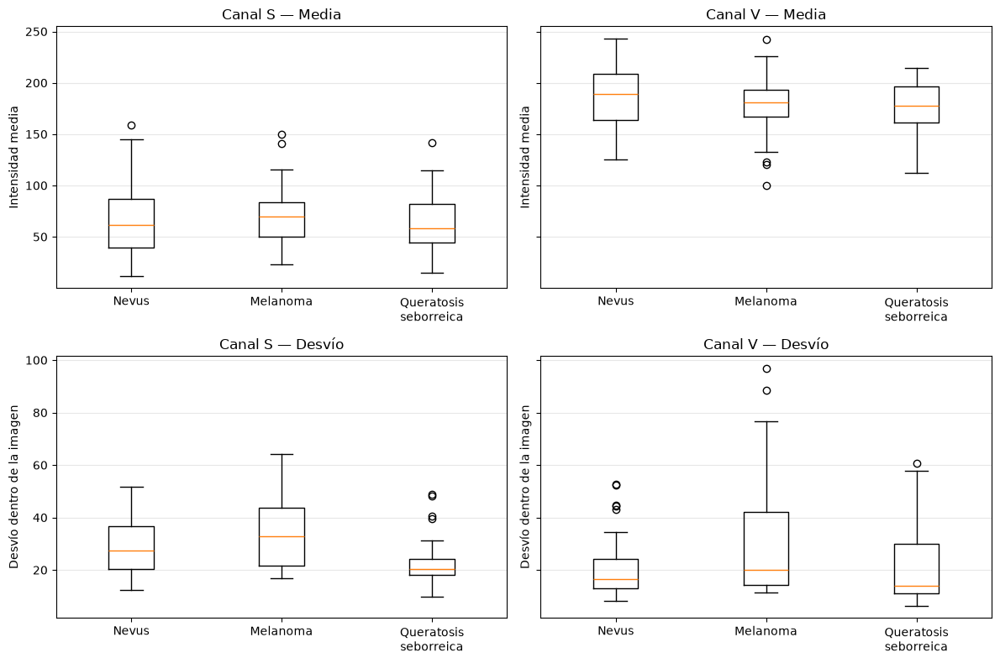

In [10]:
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey="row")

for columna, canal in enumerate(["S", "V"]):
    datos = estadisticas_canales[
        estadisticas_canales["Canal"] == canal
    ]

    for fila, estadistica in enumerate(["Media", "Desvío"]):
        valores = [
            datos.loc[datos["Diagnóstico"] == d, estadistica]
            for d in diagnosticos
        ]

        ax = axes[fila, columna]
        ax.boxplot(valores)

        ax.set_xticks([1, 2, 3])
        ax.set_xticklabels(
            ["Nevus", "Melanoma", "Queratosis\nseborreica"]
        )
        ax.set_title(f"Canal {canal} — {estadistica}")
        ax.set_ylabel(
            "Intensidad media" if fila == 0
            else "Desvío dentro de la imagen"
        )
        ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Observaciones del análisis de color e intensidad

En los tres diagnósticos, las intensidades medias siguen el orden
R > G > B. Las imágenes de nevus presentan medias RGB superiores a
las de los otros grupos y una mayor intensidad media en escala de
grises: 164,2 frente a 152,9 en melanoma y 154,3 en queratosis seborreica.

Sin embargo, los diagramas de caja muestran un amplio solapamiento
entre diagnósticos. Por lo tanto, las medias de intensidad no permiten
establecer una separación clara entre los grupos de esta muestra.

El melanoma presenta una mayor dispersión interna promedio en todos
los canales analizados. En escala de grises, esta alcanza 32,7,
frente a 23,1 en nevus y queratosis seborreica. Esto indica mayor
variación de intensidades dentro de las fotografías del grupo melanoma,
sin implicar necesariamente mayor heterogeneidad de la lesión.

Los histogramas promedio muestran diferencias en sus picos, pero
distribuciones ampliamente superpuestas. En el canal H se observan
concentraciones próximas a ambos extremos del rango, que representan
tonos cercanos debido a su naturaleza circular.

Estas mediciones incluyen lesión, piel circundante y artefactos, y pueden
estar influidas por las condiciones de adquisición. Posteriormente se
analizarán las características dentro de las máscaras para reducir
la contribución del fondo. No se han evaluado aún diferencias
estadísticamente significativas entre diagnósticos.

## Preprocesamiento: comparación de filtros de suavizado

Se aplican filtros de mediana y gaussiano, con ventanas de 3 × 3 píxeles,
a las 150 imágenes de la muestra balanceada: 50 por diagnóstico.

Cada filtro se aplica de manera independiente sobre la imagen original,
utilizando los mismos parámetros para todos los diagnósticos.

Se registran la media y el desvío de las intensidades en escala de grises
para cada imagen y variante. Además, se muestran imágenes e histogramas
de un ejemplo por diagnóstico para inspeccionar los cambios visuales.

Estas medidas describen cambios en la distribución de intensidades;
su utilidad para la segmentación se evaluará posteriormente mediante
la comparación con las máscaras de referencia.

Estos filtros no constituyen un método específico de eliminación de pelos.

In [13]:
# Esta función permite reutilizar los mismos filtros más adelante.
def aplicar_filtros(original):
    return {
        "Original": original,
        "Mediana": cv2.medianBlur(original, 3),
        "Gaussiano": cv2.GaussianBlur(original, (3, 3), 1),
    }


filas_filtros = []
diagnosticos_mostrados = set()

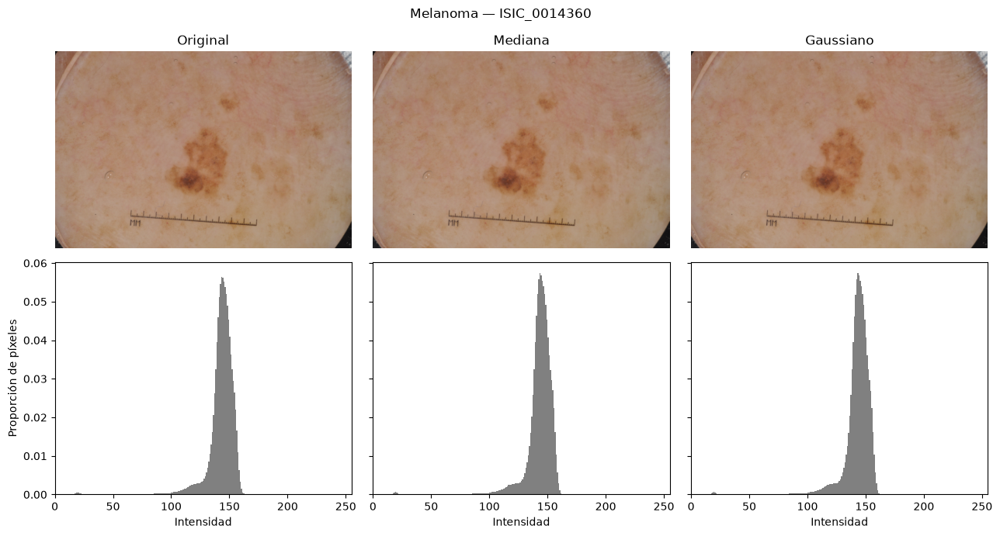

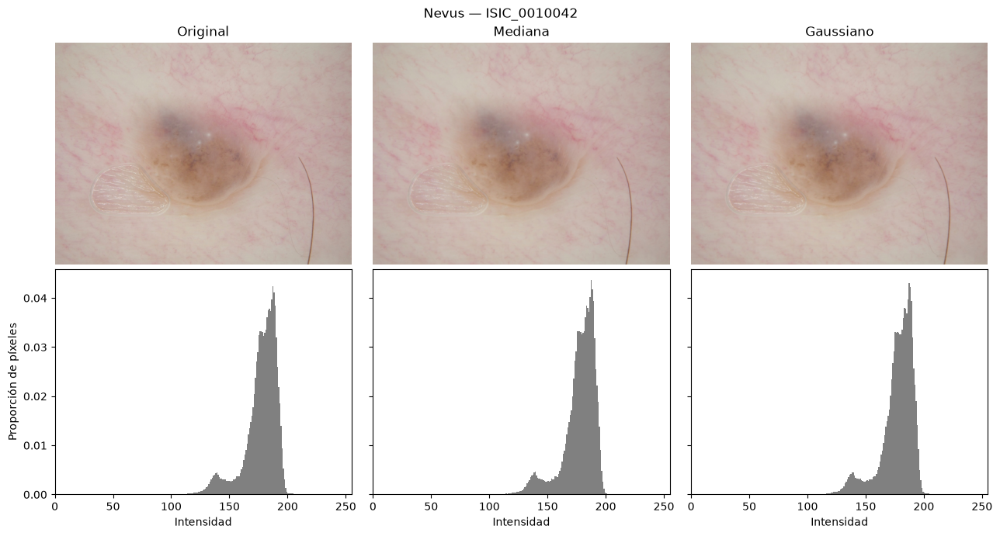

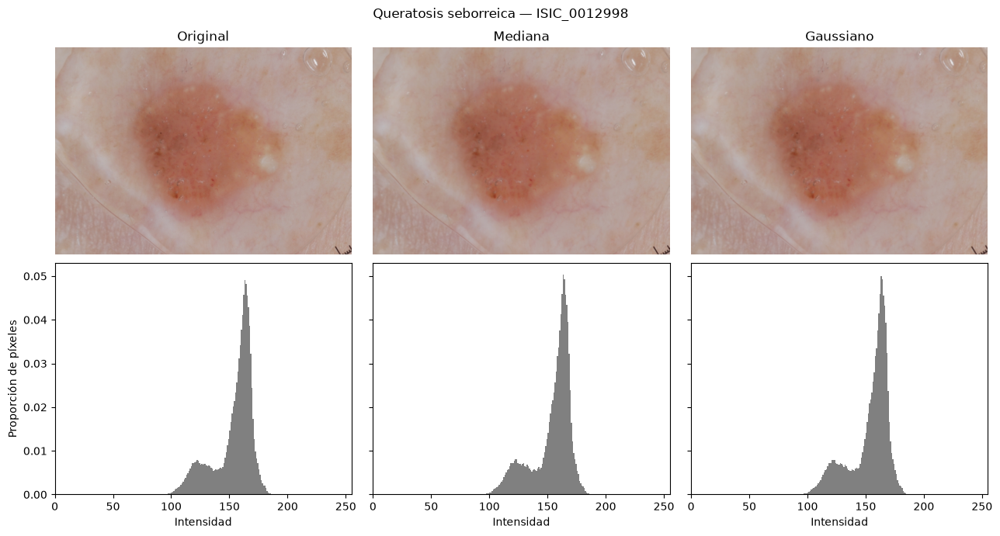

In [17]:
# Reiniciar los resultados y los ejemplos mostrados en cada ejecución.
filas_filtros = []
diagnosticos_mostrados = set()

# Procesar las mismas 150 imágenes seleccionadas previamente.
for _, registro in df_muestra.iterrows():
    # ... continúa tu código igual
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    variantes = aplicar_filtros(original)

    # Mostrar solamente un ejemplo por diagnóstico.
    mostrar = diagnostico not in diagnosticos_mostrados

    if mostrar:
        fig, axes = plt.subplots(
            2, 3, figsize=(13, 7),
            sharex="row", sharey="row"
        )
        fig.suptitle(f"{diagnostico} — {image_id}")

    for columna, (nombre, resultado) in enumerate(variantes.items()):
        gris = cv2.cvtColor(resultado, cv2.COLOR_RGB2GRAY)

        # Registrar estadísticas para TODAS las imágenes.
        filas_filtros.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Media": float(gris.mean()),
            "Desvío": float(gris.std()),
        })

        if mostrar:
            axes[0, columna].imshow(resultado)
            axes[0, columna].set_title(nombre)
            axes[0, columna].axis("off")

            axes[1, columna].hist(
                gris.ravel(),
                bins=256,
                range=(0, 256),
                density=True,
                color="gray"
            )
            axes[1, columna].set_xlabel("Intensidad")
            axes[1, columna].set_xlim(0, 255)

    if mostrar:
        axes[1, 0].set_ylabel("Proporción de píxeles")
        plt.tight_layout()
        plt.show()

        diagnosticos_mostrados.add(diagnostico)

# Una fila por imagen y variante: 150 × 3 = 450 filas.
estadisticas_filtros = pd.DataFrame(filas_filtros)


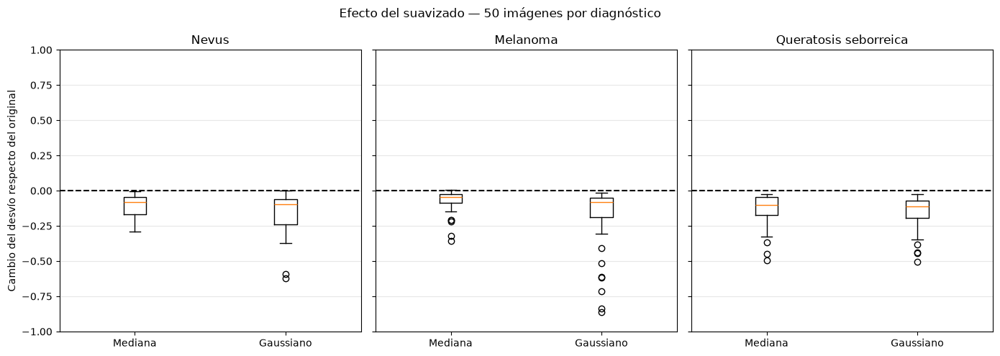

In [20]:
# Colocar las variantes de cada imagen en una misma fila.
comparacion = estadisticas_filtros.pivot(
    index=["image_id", "Diagnóstico"],
    columns="Variante",
    values="Desvío"
)

# Cambio respecto del desvío de la imagen original.
cambios = comparacion[["Mediana", "Gaussiano"]].sub(
    comparacion["Original"], axis=0
)

diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)

for ax, diagnostico in zip(axes, diagnosticos):
    datos = cambios.xs(diagnostico, level="Diagnóstico")

    ax.boxplot([datos["Mediana"], datos["Gaussiano"]])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Mediana", "Gaussiano"])
    ax.axhline(0, color="black", linestyle="--")
    ax.set_title(diagnostico)
    ax.set_ylim(-1, 1)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Cambio del desvío respecto del original")
fig.suptitle("Efecto del suavizado — 50 imágenes por diagnóstico")

plt.tight_layout()
plt.show()

### Observaciones sobre los filtros de suavizado

Los filtros de mediana y gaussiano de 3 × 3 producen cambios pequeños
en las estadísticas globales de las imágenes. En los tres diagnósticos,
se observa una ligera disminución del desvío de intensidades respecto
del original.

El filtro gaussiano presenta reducciones más pronunciadas en algunas
imágenes, especialmente en el grupo melanoma. Sin embargo, existe
superposición entre los resultados de ambos filtros.

La disminución del desvío indica una menor variabilidad de intensidades,
pero no permite distinguir entre reducción de ruido y pérdida de detalles.
Por ello, la elección del filtro se apoyará en su efecto sobre la
segmentación, evaluado mediante las máscaras de referencia.

### Inspección ampliada y comparación cuantitativa del suavizado

Se comparan filtros de mediana y gaussianos con ventanas de 3 × 3
y 5 × 5 píxeles sobre las 150 imágenes, utilizando los mismos
parámetros para todos los diagnósticos.

Para observar los detalles locales, se muestra un recorte central de
150 × 150 píxeles de un ejemplo por diagnóstico. Este recorte se utiliza
solo para visualización y no representa necesariamente toda la lesión.
Los filtros se aplican sobre la imagen completa antes de recortarla.

La comparación cuantitativa se realiza sobre las imágenes completas
en escala de grises mediante:

- **Magnitud media del gradiente Sobel:** describe las variaciones locales
  de intensidad. Puede disminuir por suavizado de bordes, detalles o ruido;
  por sí sola no determina la calidad de la imagen.
- **PSNR respecto de la original:** cuantifica la similitud con la imagen
  sin filtrar. Un valor mayor indica menor modificación, pero no demuestra
  una mejor eliminación de ruido.

La media y el desvío de intensidades ya fueron analizados en el bloque
anterior. La utilidad de los filtros se evaluará posteriormente mediante
su efecto sobre la segmentación.

In [22]:
def variantes_suavizado(original):
    return {
        "Original": original,
        "Mediana 3×3": cv2.medianBlur(original, 3),
        "Gaussiano 3×3": cv2.GaussianBlur(original, (3, 3), 1),
        "Mediana 5×5": cv2.medianBlur(original, 5),
        "Gaussiano 5×5": cv2.GaussianBlur(original, (5, 5), 1.5),
    }


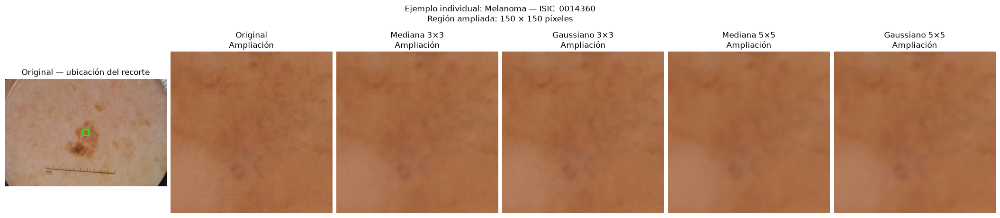

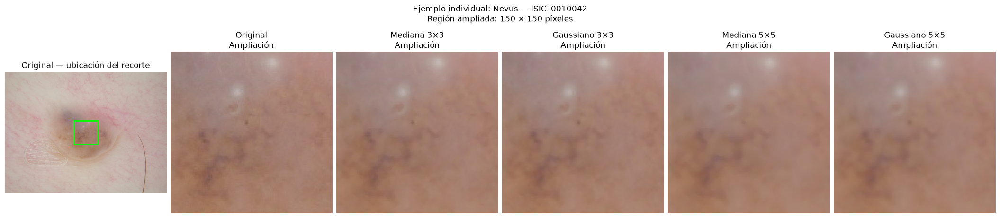

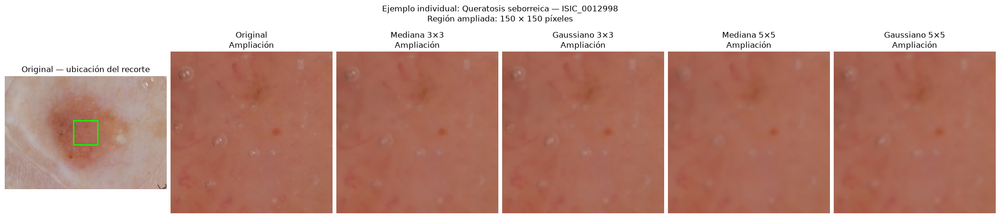

In [23]:
filas_detalle = []
diagnosticos_mostrados = set()

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    gris_original = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    variantes = variantes_suavizado(original)

    # Las métricas se calculan para las 150 imágenes completas.
    for nombre, resultado in variantes.items():
        gris = cv2.cvtColor(resultado, cv2.COLOR_RGB2GRAY)

        gx = cv2.Sobel(gris, cv2.CV_64F, 1, 0, ksize=3)
        gy = cv2.Sobel(gris, cv2.CV_64F, 0, 1, ksize=3)
        gradiente = np.hypot(gx, gy).mean()

        # Convertir a float antes de restar evita errores con uint8.
        diferencia = gris.astype(float) - gris_original.astype(float)
        mse = np.mean(diferencia ** 2)

        psnr = (
            np.inf if mse == 0
            else 10 * np.log10(255 ** 2 / mse)
        )

        filas_detalle.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Gradiente medio": gradiente,
            "PSNR (dB)": psnr,
        })

        # Mostrar un ejemplo por diagnóstico.
    if diagnostico not in diagnosticos_mostrados:
        alto, ancho = original.shape[:2]

        lado = min(150, alto, ancho)
        y0 = (alto - lado) // 2
        x0 = (ancho - lado) // 2

        fig, axes = plt.subplots(
            1, 6, figsize=(21, 5), constrained_layout=True
        )
        fig.suptitle(
            f"Ejemplo individual: {diagnostico} — {image_id}\n"
            f"Región ampliada: {lado} × {lado} píxeles"
        )

        # Original completa con el recuadro de la región ampliada.
        axes[0].imshow(original)

        recuadro = plt.Rectangle(
            (x0, y0), lado, lado,
            edgecolor="lime",
            facecolor="none",
            linewidth=2
        )
        axes[0].add_patch(recuadro)
        axes[0].set_title("Original — ubicación del recorte")
        axes[0].axis("off")

        # Misma región para todas las variantes.
        for ax, (nombre, resultado) in zip(axes[1:], variantes.items()):
            recorte = resultado[y0:y0 + lado, x0:x0 + lado]

            ax.imshow(recorte, interpolation="nearest")
            ax.set_title(f"{nombre}\nAmpliación")
            ax.axis("off")

        plt.show()
        diagnosticos_mostrados.add(diagnostico)

estadisticas_detalle = pd.DataFrame(filas_detalle)

In [24]:
# Reutilizar las métricas calculadas sobre las 150 imágenes.
metricas_suavizado = estadisticas_detalle.copy()

# El PSNR de imágenes idénticas es infinito:
# se excluye del resumen para evitar promediar infinitos.
metricas_suavizado["PSNR (dB)"] = (
    metricas_suavizado["PSNR (dB)"].replace(np.inf, np.nan)
)

orden = [
    "Original",
    "Mediana 3×3",
    "Gaussiano 3×3",
    "Mediana 5×5",
    "Gaussiano 5×5",
]

resumen_suavizado = metricas_suavizado.groupby(
    ["Diagnóstico", "Variante"]
).agg(
    Cantidad=("image_id", "nunique"),
    Gradiente_promedio=("Gradiente medio", "mean"),
    PSNR_promedio_dB=("PSNR (dB)", "mean"),
)

# Mostrar las variantes en el orden de las figuras.
resumen_suavizado = resumen_suavizado.reindex(
    pd.MultiIndex.from_product(
        [sorted(metricas_suavizado["Diagnóstico"].unique()), orden],
        names=["Diagnóstico", "Variante"]
    )
)

display(resumen_suavizado.round(2))

Cantidad  Gradiente_promedio  \
Diagnóstico           Variante                                      
Melanoma              Original             50               13.89   
                      Mediana 3×3          50               10.60   
                      Gaussiano 3×3        50               10.59   
                      Mediana 5×5          50                7.99   
                      Gaussiano 5×5        50                8.51   
Nevus                 Original             50               12.84   
                      Mediana 3×3          50                9.58   
                      Gaussiano 3×3        50                9.82   
                      Mediana 5×5          50                7.33   
                      Gaussiano 5×5        50                7.86   
Queratosis seborreica Original             50               13.64   
                      Mediana 3×3          50               10.02   
                      Gaussiano 3×3        50               10.36   
                      Mediana 5×5          50                7.54   
                      Gaussiano 5×5        50                8.23   

                                     PSNR_promedio_dB  
Diagnóstico           Variante                         
Melanoma              Original                    NaN  
                      Mediana 3×3               46.05  
                      Gaussiano 3×3             44.50  
                      Mediana 5×5               41.66  
                      Gaussiano 5×5             41.46  
Nevus                 Original                    NaN  
                      Mediana 3×3               46.10  
                      Gaussiano 3×3             46.30  
                      Mediana 5×5               42.64  
                      Gaussiano 5×5             43.07  
Queratosis seborreica Original                    NaN  
                      Mediana 3×3               45.81  
                      Gaussiano 3×3             46.33  
                      Mediana 5×5               42.26  
                      Gaussiano 5×5             42.93

### Resultado de la comparación cuantitativa

La comparación incluye las 150 imágenes, con 50 muestras por diagnóstico.
Los filtros producen cambios pequeños en la media y el desvío global
de intensidades, pero reducen la magnitud media del gradiente Sobel.

Respecto del gradiente promedio original de cada diagnóstico, la reducción
es aproximadamente del 23–27 % con las ventanas de 3 × 3 y del 39–45 %
con las de 5 × 5. Esto indica una atenuación de las variaciones locales
de intensidad, que pueden corresponder a bordes, textura o ruido.

El PSNR promedio se encuentra entre 44,5 y 46,3 dB para los filtros
de 3 × 3, y entre 41,5 y 43,1 dB para los de 5 × 5. Las ventanas
mayores introducen una modificación más marcada respecto de la original.
Estos valores describen similitud y no demuestran una mejora de calidad.

En los ejemplos ampliados, las ventanas de 5 × 5 suavizan más los detalles
locales. Las diferencias entre mediana y gaussiano dependen de la imagen
y del tamaño de ventana; no se identifica un filtro superior para todos
los diagnósticos a partir de estas medidas.

Se priorizan inicialmente las ventanas de 3 × 3 por introducir menores
modificaciones. La elección definitiva se realizará evaluando su efecto
sobre la segmentación mediante las máscaras de referencia. Para la
caracterización de color y textura se conservarán las imágenes originales.

## Pruebas de mejora de contraste

Se comparan la ecualización global del histograma y la ecualización
adaptativa con limitación de contraste (CLAHE) sobre las 150 imágenes,
con 50 muestras por diagnóstico.

Ambos métodos se aplican de forma independiente sobre la imagen original
en escala de grises, sin suavizado previo y utilizando los mismos
parámetros para todos los diagnósticos.

Se muestran los mismos ejemplos individuales de la comparación de filtros.
Para el conjunto completo se registran la media y el desvío de intensidades.

El objetivo es estudiar los cambios de contraste y su efecto sobre detalles
y artefactos. Su utilidad para la segmentación se evaluará posteriormente
mediante las máscaras de referencia. Las imágenes originales se conservan
para la caracterización de color y textura.

In [25]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)  # Grilla de 8 × 8 regiones.
)

In [26]:
def aplicar_contraste(gris):
    return {
        "Original en gris": gris,
        "Ecualización global": cv2.equalizeHist(gris),
        "CLAHE": clahe.apply(gris),
    }

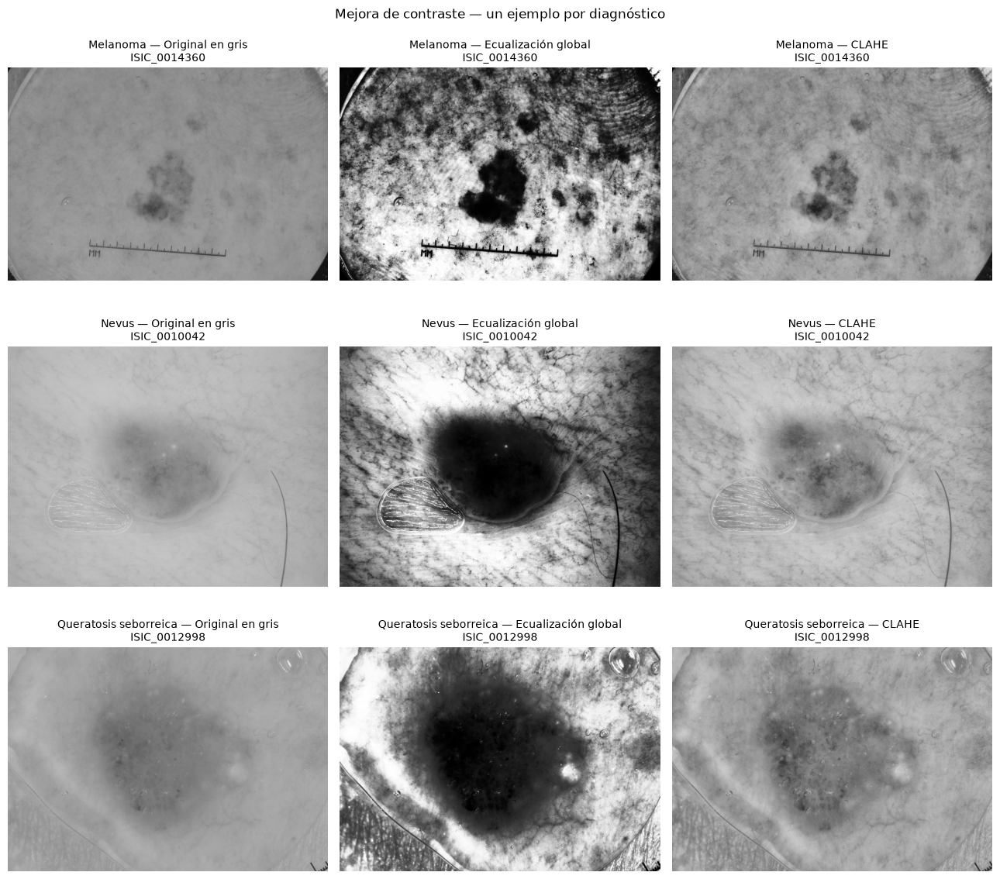

In [28]:
filas_contraste = []

# Guardar solo los ejemplos para visualizarlos y reutilizarlos.
contraste = {}

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    variantes = aplicar_contraste(gris)

    # Estadísticas de las 150 imágenes.
    for nombre, resultado in variantes.items():
        filas_contraste.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Media": float(resultado.mean()),
            "Desvío": float(resultado.std()),
        })

    # Mostrar la primera imagen de cada diagnóstico,
    # igual que en el bloque de suavizado.
    if diagnostico not in contraste:
        fila = len(contraste)
        contraste[diagnostico] = variantes

        for columna, (nombre, resultado) in enumerate(variantes.items()):
            axes[fila, columna].imshow(
                resultado, cmap="gray", vmin=0, vmax=255
            )
            axes[fila, columna].set_title(
                f"{diagnostico} — {nombre}\n{image_id}",
                fontsize=10
            )
            axes[fila, columna].axis("off")

fig.suptitle("Mejora de contraste — un ejemplo por diagnóstico")
plt.tight_layout()
plt.show()

estadisticas_contraste = pd.DataFrame(filas_contraste)


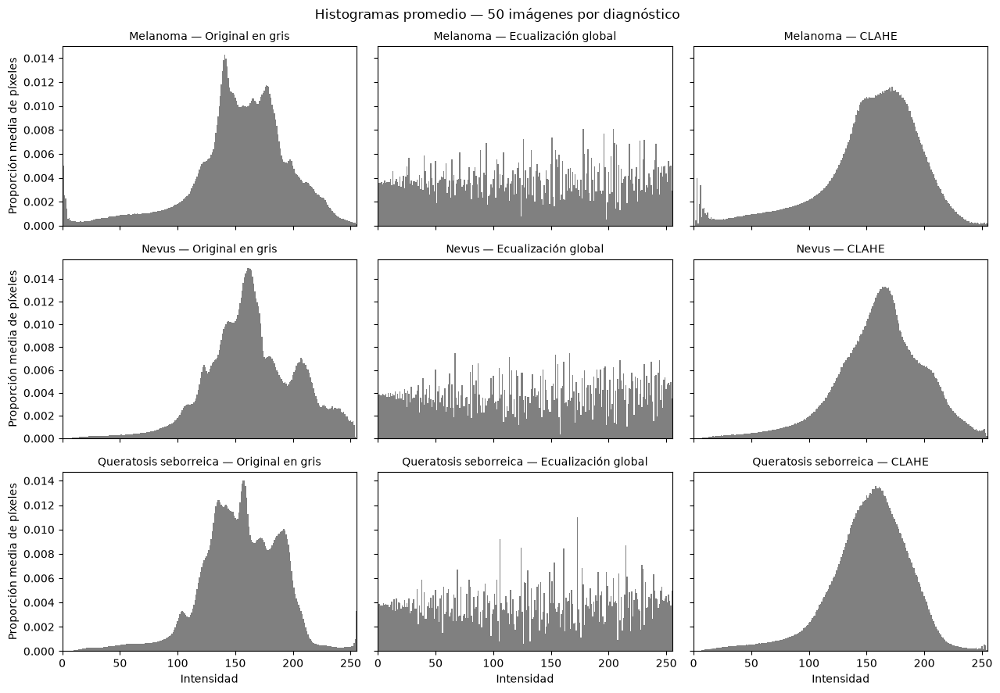

In [29]:
# Acumular histogramas, sin guardar todas las imágenes en memoria.
histogramas_contraste = {}
cantidades = {}

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    variantes = aplicar_contraste(gris)

    if diagnostico not in histogramas_contraste:
        histogramas_contraste[diagnostico] = {
            nombre: np.zeros(256) for nombre in variantes
        }
        cantidades[diagnostico] = 0

    for nombre, resultado in variantes.items():
        hist = cv2.calcHist(
            [resultado], [0], None, [256], [0, 256]
        ).ravel()

        # Normalizar antes de acumular: cada imagen pesa lo mismo.
        histogramas_contraste[diagnostico][nombre] += hist / hist.sum()

    cantidades[diagnostico] += 1


fig, axes = plt.subplots(
    3, 3, figsize=(13, 9),
    sharex=True, sharey="row"
)

for fila, (diagnostico, variantes) in enumerate(
    histogramas_contraste.items()
):
    for columna, (nombre, suma_hist) in enumerate(variantes.items()):
        ax = axes[fila, columna]

        hist_promedio = suma_hist / cantidades[diagnostico]

        ax.bar(
            np.arange(256), hist_promedio,
            width=1, color="gray"
        )
        ax.set_title(f"{diagnostico} — {nombre}", fontsize=10)
        ax.set_xlim(0, 255)

        if fila == 2:
            ax.set_xlabel("Intensidad")
        if columna == 0:
            ax.set_ylabel("Proporción media de píxeles")

fig.suptitle(
    "Histogramas promedio — 50 imágenes por diagnóstico"
)
plt.tight_layout()
plt.show()

### Resultados de las pruebas de mejora de contraste

En los histogramas promedio de las 50 imágenes por diagnóstico, la
ecualización global redistribuye las intensidades sobre un rango más
amplio y genera distribuciones más uniformes, aunque con picos y
discontinuidades propios de la transformación de niveles discretos.

En los ejemplos individuales, esta transformación aumenta marcadamente
el contraste de las lesiones, pero también realza la textura de la piel,
las marcas de escala, los pelos y los reflejos. Por lo tanto, un mayor
contraste visual no implica necesariamente una mejor segmentación.

CLAHE produce un realce más moderado en los ejemplos mostrados. Sus
histogramas promedio conservan una concentración de intensidades más
marcada que los obtenidos mediante ecualización global. También se
acentúan detalles de la piel y artefactos, aunque visualmente con menor
intensidad en estos ejemplos.

Se mantienen la imagen sin ecualizar y ambas alternativas para comparar
su efecto sobre la segmentación mediante Dice e IoU respecto de las
máscaras de referencia. Estos resultados aún no permiten establecer
qué método ofrece el mejor desempeño.

### Comparación cuantitativa de la mejora de contraste

Se comparan las variantes sin ecualizar, con ecualización global y con
CLAHE sobre las 150 imágenes, con 50 muestras por diagnóstico.

Se reutilizan la media y el desvío de intensidades calculados previamente.
Como análisis adicional, se mide la separación de intensidades entre la
lesión y el fondo, definidos mediante la máscara de referencia.

El indicador se calcula como la diferencia absoluta entre sus intensidades
medias, dividida por el desvío global de la imagen. Esta normalización
permite comparar la separación relativa entre regiones.

El fondo puede incluir artefactos y no se considera exclusivamente piel
sana. El indicador describe una separación de intensidades y no mide
directamente la precisión de la segmentación.

Las máscaras de referencia se utilizan únicamente para este análisis
y para evaluar los resultados; no intervienen en el preprocesamiento
ni en la generación de las segmentaciones.

In [30]:
def separacion_lesion_fondo(gris, mascara):
    """
    Diferencia absoluta entre las medias de lesión y fondo,
    dividida por el desvío global.

    mascara: máscara de referencia, con la lesión en blanco.
    """
    if gris.shape != mascara.shape:
        raise ValueError("La imagen y la máscara deben tener igual tamaño.")

    lesion = mascara > 0
    fondo = ~lesion

    desvio = gris.std()

    # El indicador no está definido si falta una región
    # o si la imagen tiene intensidad constante.
    if not lesion.any() or not fondo.any() or desvio == 0:
        return np.nan

    return abs(
        gris[lesion].mean() - gris[fondo].mean()
    ) / desvio

In [32]:
# Ajustar si las máscaras están en otra ubicación.
carpeta_mascaras = Path("Data/ISIC-2017_Training_Part1_GroundTruth")

filas_separacion = []

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))

    ruta_mascara = carpeta_mascaras / f"{image_id}_segmentation.png"
    mascara = cv2.imread(str(ruta_mascara), cv2.IMREAD_GRAYSCALE)

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    if mascara is None:
        raise FileNotFoundError(f"No se pudo leer la máscara: {ruta_mascara}")

    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

    # Misma función y parámetros utilizados en las figuras anteriores.
    variantes = aplicar_contraste(gris)

    for nombre, resultado in variantes.items():
        filas_separacion.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Separación lesión-fondo": separacion_lesion_fondo(
                resultado, mascara
            ),
        })

# Agregar la separación a las estadísticas previamente calculadas.
metricas_contraste = estadisticas_contraste.merge(
    pd.DataFrame(filas_separacion),
    on=["image_id", "Diagnóstico", "Variante"],
    validate="one_to_one"
)

# Cada fila del resumen corresponde a 50 imágenes.
resumen_contraste = metricas_contraste.groupby(
    ["Diagnóstico", "Variante"]
).agg(
    Cantidad=("image_id", "nunique"),
    Media_promedio=("Media", "mean"),
    Desvío_interno_promedio=("Desvío", "mean"),
    Separación_promedio=("Separación lesión-fondo", "mean"),
)

display(resumen_contraste.round(2))

Cantidad  Media_promedio  \
Diagnóstico           Variante                                        
Melanoma              CLAHE                      50          152.88   
                      Ecualización global        50          129.90   
                      Original en gris           50          152.93   
Nevus                 CLAHE                      50          161.42   
                      Ecualización global        50          131.36   
                      Original en gris           50          164.22   
Queratosis seborreica CLAHE                      50          152.35   
                      Ecualización global        50          131.23   
                      Original en gris           50          154.29   

                                           Desvío_interno_promedio  \
Diagnóstico           Variante                                       
Melanoma              CLAHE                                  37.54   
                      Ecualización global                    74.65   
                      Original en gris                       32.67   
Nevus                 CLAHE                                  29.85   
                      Ecualización global                    74.58   
                      Original en gris                       23.12   
Queratosis seborreica CLAHE                                  29.47   
                      Ecualización global                    74.50   
                      Original en gris                       23.08   

                                           Separación_promedio  
Diagnóstico           Variante                                  
Melanoma              CLAHE                               1.35  
                      Ecualización global                 1.32  
                      Original en gris                    1.56  
Nevus                 CLAHE                               1.70  
                      Ecualización global                 1.40  
                      Original en gris                    1.92  
Queratosis seborreica CLAHE                               1.12  
                      Ecualización global                 1.23  
                      Original en gris                    1.31

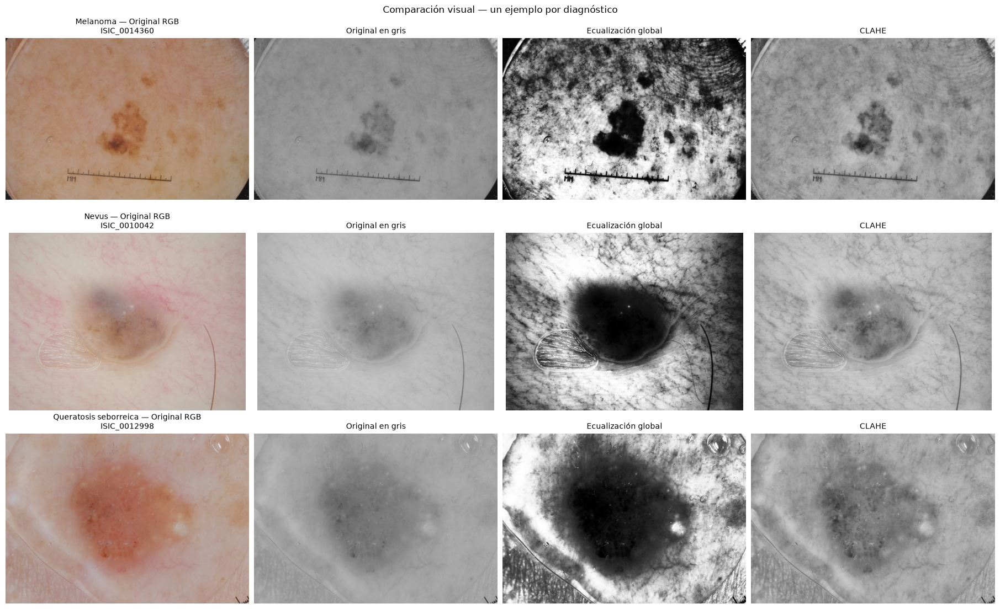

In [33]:
fig, axes = plt.subplots(
    3, 4, figsize=(18, 11), constrained_layout=True
)

for fila, (diagnostico, variantes) in enumerate(contraste.items()):
    # Recuperar el mismo ejemplo mostrado en el bloque de contraste.
    registro = df_muestra[
        df_muestra["diagnostico"] == diagnostico
    ].iloc[0]

    image_id = registro["image_id"]
    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Primera columna: original en color.
    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(
        f"{diagnostico} — Original RGB\n{image_id}", fontsize=10
    )

    # Columnas restantes: variantes ya calculadas.
    for columna, (nombre, resultado) in enumerate(variantes.items(), 1):
        axes[fila, columna].imshow(
            resultado, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(nombre, fontsize=10)

    for ax in axes[fila]:
        ax.axis("off")

fig.suptitle("Comparación visual — un ejemplo por diagnóstico")
plt.show()

### Resultado de la comparación cuantitativa del contraste

En las 150 imágenes analizadas, la ecualización global aumenta el
desvío interno promedio desde 23,1–32,7 hasta aproximadamente 74,5
niveles de gris y desplaza la intensidad media hacia valores de
130–131. CLAHE produce cambios más moderados: el desvío interno
promedio alcanza valores de 29,5–37,5 y la media permanece más
próxima a la original.

Sin embargo, ambos métodos reducen la separación promedio normalizada
entre lesión y fondo, calculada mediante las máscaras de referencia.
En melanoma, pasa de 1,56 a 1,35 con CLAHE y 1,32 con ecualización
global; en nevus, de 1,92 a 1,70 y 1,40; y en queratosis seborreica,
de 1,31 a 1,12 y 1,23, respectivamente.

Por lo tanto, el aumento del contraste global no se traduce en una
mayor separación relativa de las intensidades medias de lesión y fondo.
Estas comparaciones son descriptivas y no se ha evaluado su
significación estadística.

En los ejemplos visuales, la ecualización global realza marcadamente
tanto las lesiones como la textura de la piel y los artefactos.
CLAHE presenta un realce más moderado, aunque también acentúa
estructuras del fondo.

Se compararán las tres variantes —sin ecualizar, con ecualización
global y con CLAHE— en la segmentación posterior, evaluando sus
resultados mediante Dice e IoU. Las características de color y textura
se calcularán sobre las imágenes originales, dentro de las regiones
seleccionadas por las máscaras.

## Detección de posibles pelos y artefactos oscuros

Los pelos y otros artefactos oscuros pueden generar bordes que interfieren
en la segmentación. Se explora su detección mediante la transformación
black-hat sobre la imagen original en escala de grises, sin ecualización
ni suavizado previo.

El black-hat se calcula como la diferencia entre el cierre morfológico
y la imagen original. Resalta estructuras oscuras cuya forma y tamaño
permiten que sean rellenadas por el cierre. Su respuesta se umbraliza
para obtener una máscara de posibles artefactos.

Se evalúan elementos estructurantes elípticos de 9 × 9, 17 × 17 y
25 × 25 píxeles, combinados con umbrales de 20, 30, 40 y 50.
Las mismas combinaciones se aplican a las 150 imágenes, con 50 por
diagnóstico.

Para cada combinación se registra el porcentaje de píxeles marcados.
Este porcentaje describe la extensión de la detección, pero no su
precisión: también pueden marcarse estructuras propias de la lesión.

Los tamaños se expresan en píxeles, por lo que su efecto depende de
la resolución y de la escala de las estructuras en cada imagen.
La elección de parámetros requerirá inspección visual y evaluación
de su efecto sobre la segmentación posterior.

En los bloques siguientes se evaluarán el refinamiento morfológico
de las máscaras y la corrección mediante inpainting.

### Ejemplos para la inspección de pelos

Se seleccionan las imágenes ISIC_0000018, ISIC_0000012, ISIC_0000019
e ISIC_0000032 por la presencia visible de pelos, para inspeccionar
las máscaras de detección y los resultados de la corrección.

Estos cuatro casos constituyen ejemplos de exploración visual.
La evaluación general del procesamiento se mantiene sobre la muestra
balanceada de 150 imágenes.

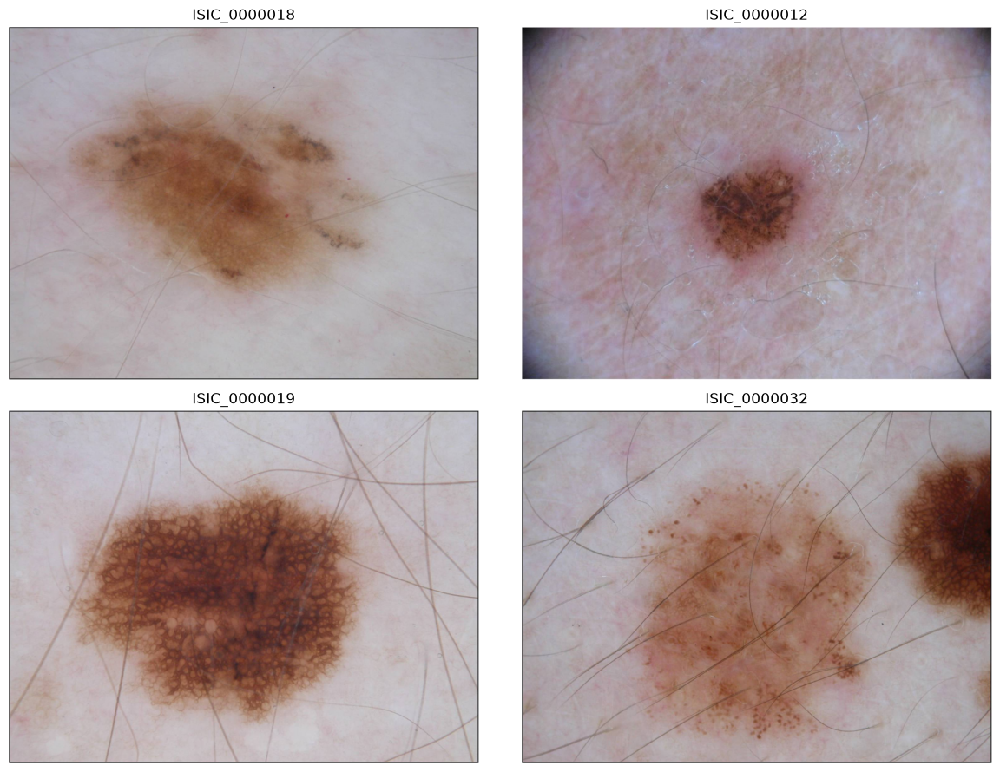

In [35]:
# Ejemplos específicos para inspeccionar pelos.
ids_pelos = [
    "ISIC_0000018",
    "ISIC_0000012",
    "ISIC_0000019",
    "ISIC_0000032",
]

imagenes_pelos = {}

for image_id in ids_pelos:
    if image_id not in rutas:
        raise FileNotFoundError(f"No se encontró {image_id} en rutas.")

    imagen = cv2.imread(str(rutas[image_id]))

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    imagenes_pelos[image_id] = cv2.cvtColor(
        imagen, cv2.COLOR_BGR2RGB
    )

# Mostrar los cuatro ejemplos.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (image_id, original) in zip(axes.ravel(), imagenes_pelos.items()):
    ax.imshow(original)
    ax.set_title(image_id)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [36]:
tamanios_kernel = [9, 17, 25]
umbrales = [20, 30, 40, 50]

filas_artefactos = []

# Evaluar los cuatro ejemplos seleccionados por presencia de pelos.
for image_id, original in imagenes_pelos.items():
    # Las imágenes de este diccionario están en RGB.
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    for tamanio in tamanios_kernel:
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (tamanio, tamanio)
        )

        blackhat = cv2.morphologyEx(
            gris, cv2.MORPH_BLACKHAT, kernel
        )

        for umbral in umbrales:
            filas_artefactos.append({
                "image_id": image_id,
                "Kernel": tamanio,
                "Umbral": umbral,
                "Porcentaje marcado": 100 * (blackhat > umbral).mean(),
            })

barrido_parametros = pd.DataFrame(filas_artefactos)

# Cada fila corresponde a una imagen y un tamaño de kernel.
tabla_barrido = barrido_parametros.pivot(
    index=["image_id", "Kernel"],
    columns="Umbral",
    values="Porcentaje marcado"
)

print("Porcentaje de píxeles marcados como posibles artefactos:")
display(tabla_barrido.round(2))

Porcentaje de píxeles marcados como posibles artefactos:


Umbral                 20    30    40    50
image_id     Kernel                        
ISIC_0000012 9       0.22  0.03  0.00  0.00
             17      0.85  0.13  0.02  0.01
             25      2.21  0.38  0.06  0.02
ISIC_0000018 9       0.66  0.62  0.62  0.62
             17      0.72  0.63  0.62  0.62
             25      0.82  0.64  0.62  0.62
ISIC_0000019 9       1.47  0.83  0.66  0.63
             17      3.35  1.45  0.81  0.66
             25      5.50  1.89  0.87  0.68
ISIC_0000032 9       2.32  1.30  0.80  0.61
             17      3.64  2.01  1.12  0.71
             25      4.38  2.31  1.26  0.78

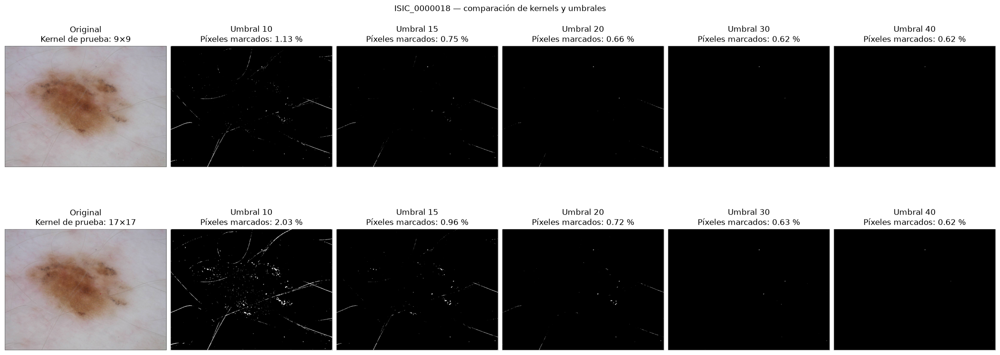

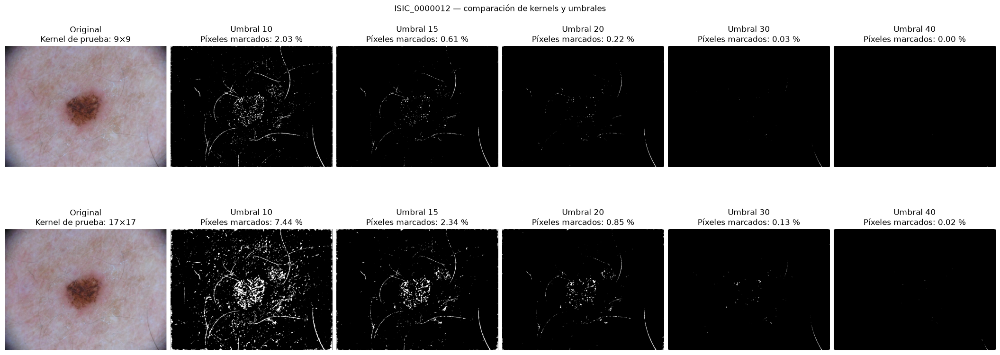

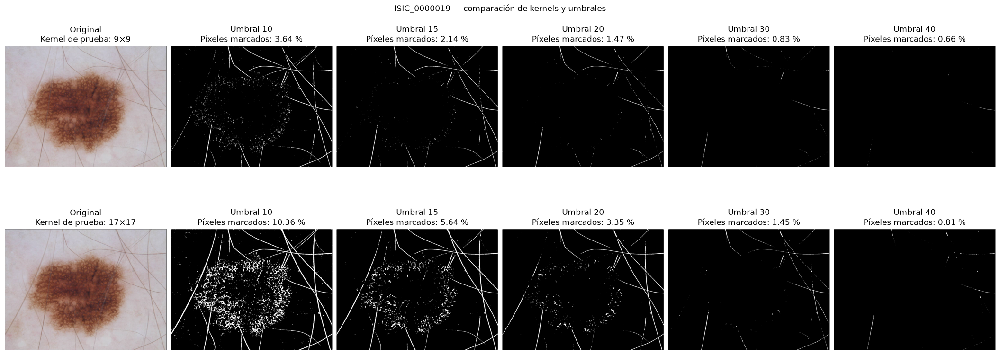

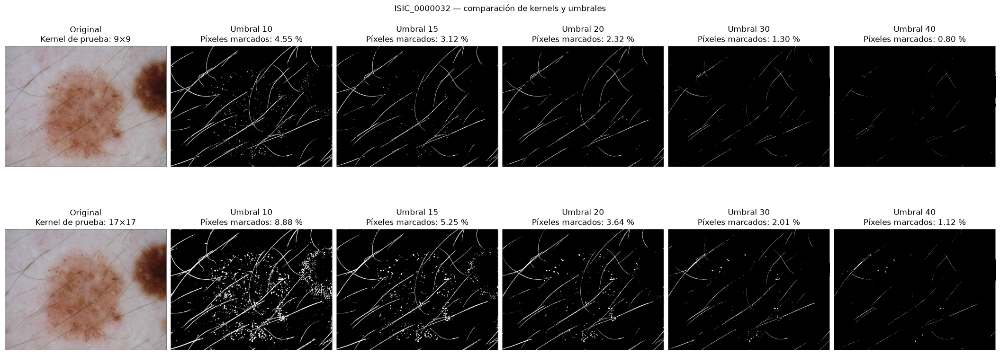

In [42]:
tamanios_prueba = [9, 17]
umbrales_prueba = [10, 15, 20, 30, 40]

for image_id, original in imagenes_pelos.items():
    gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    fig, axes = plt.subplots(
        len(tamanios_prueba),
        len(umbrales_prueba) + 1,
        figsize=(21, 4 * len(tamanios_prueba)),
        constrained_layout=True,
        squeeze=False
    )
    fig.suptitle(f"{image_id} — comparación de kernels y umbrales")

    for fila, tamanio in enumerate(tamanios_prueba):
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (tamanio, tamanio)
        )

        blackhat = cv2.morphologyEx(
            gris, cv2.MORPH_BLACKHAT, kernel
        )

        # Original como referencia en cada fila.
        axes[fila, 0].imshow(original)
        axes[fila, 0].set_title(
            f"Original\nKernel de prueba: {tamanio}×{tamanio}"
        )
        axes[fila, 0].axis("off")

        for columna, umbral in enumerate(umbrales_prueba, start=1):
            mascara = (blackhat > umbral).astype(np.uint8) * 255
            porcentaje = 100 * (mascara > 0).mean()

            axes[fila, columna].imshow(
                mascara, cmap="gray", vmin=0, vmax=255
            )
            axes[fila, columna].set_title(
                f"Umbral {umbral}\n"
                f"Píxeles marcados: {porcentaje:.2f} %"
            )
            axes[fila, columna].axis("off")

    plt.show()

### Resultado del barrido de parámetros

La detección presenta diferencias entre los cuatro ejemplos. Los umbrales
de 40 y 50 omiten gran parte de los pelos visibles, mientras que los
kernels mayores incorporan más estructuras de la lesión.

Se selecciona inicialmente un kernel de 9 × 9 y un umbral de 20 como
compromiso visual entre detección de pelos y preservación de la textura.
Esta combinación presenta detecciones incompletas, especialmente en
ISIC_0000018 e ISIC_0000012, y no se considera una solución definitiva.

A continuación se evaluará el refinamiento de la máscara mediante cierre
y dilatación, seguido de inpainting. La evaluación de estos cuatro casos
es exploratoria y no permite generalizar el desempeño a toda la muestra.

### Elección de parámetros

El barrido muestra que aumentar el tamaño del elemento estructurante
y reducir el umbral incrementa el porcentaje de píxeles marcados.
Sin embargo, este aumento no implica una mejor detección de pelos:
también pueden incorporarse estructuras propias de la lesión.

Con umbral 20, al aumentar el kernel de 9 × 9 a 25 × 25, el porcentaje
marcado pasa de 0,22 % a 2,21 % en ISIC_0000012, de 1,47 % a 5,50 %
en ISIC_0000019 y de 2,32 % a 4,38 % en ISIC_0000032. En las máscaras
se observa que los kernels mayores incorporan más textura de la lesión,
especialmente en los dos primeros casos.

En ISIC_0000018, el porcentaje permanece próximo al 0,62 % para los
umbrales de 30 a 50, con escasa variación entre kernels. Esta estabilidad
no demuestra una detección adecuada: visualmente, muchos pelos no
quedan representados en las máscaras.

Los umbrales de 40 y 50 omiten gran parte de los pelos visibles.
Se seleccionan inicialmente un kernel de 9 × 9 y un umbral de 20
como compromiso entre detectar pelos y limitar la inclusión de
estructuras de la lesión. Con estos parámetros se marca el 0,22 %,
0,66 %, 1,47 % y 2,32 % de los píxeles en ISIC_0000012,
ISIC_0000018, ISIC_0000019 e ISIC_0000032, respectivamente.

La detección sigue siendo incompleta, especialmente en ISIC_0000012
e ISIC_0000018. Por ello, la selección es exploratoria y se comparará
el refinamiento mediante apertura y mediante cierre seguido de
dilatación. Su utilidad final se evaluará por el efecto de la corrección
sobre la segmentación.

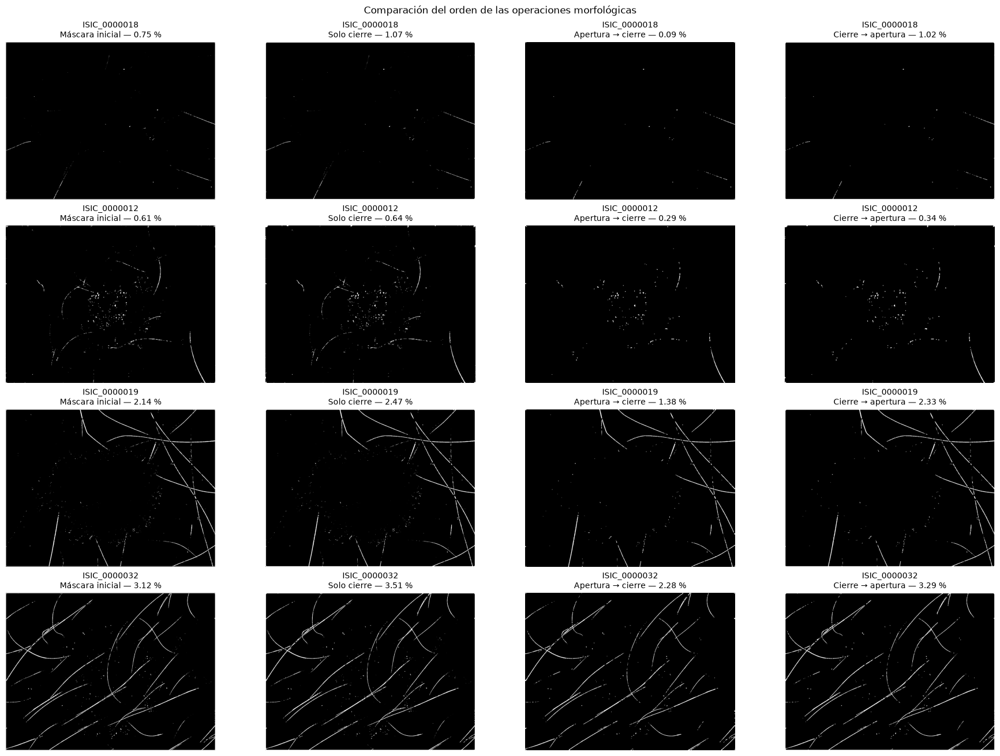

In [44]:
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

mascaras_refinadas = {}

fig, axes = plt.subplots(
    len(imagenes_pelos), 4,
    figsize=(18, 13),
    constrained_layout=True
)

fig.suptitle("Comparación del orden de las operaciones morfológicas")

for fila, image_id in enumerate(imagenes_pelos):
    mascara = mascaras_artefactos[image_id]["Máscara inicial"]

    # Apertura seguida de cierre.
    apertura = cv2.morphologyEx(
        mascara, cv2.MORPH_OPEN, kernel
    )
    apertura_cierre = cv2.morphologyEx(
        apertura, cv2.MORPH_CLOSE, kernel
    )

    # Cierre seguido de apertura.
    cierre = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel
    )
    cierre_apertura = cv2.morphologyEx(
        cierre, cv2.MORPH_OPEN, kernel
    )

    paneles = {
        "Máscara inicial": mascara,
        "Solo cierre": cierre,
        "Apertura → cierre": apertura_cierre,
        "Cierre → apertura": cierre_apertura,
    }

    mascaras_refinadas[image_id] = paneles

    for columna, (nombre, resultado) in enumerate(paneles.items()):
        porcentaje = 100 * (resultado > 0).mean()

        axes[fila, columna].imshow(
            resultado, cmap="gray", vmin=0, vmax=255
        )
        axes[fila, columna].set_title(
            f"{image_id}\n{nombre} — {porcentaje:.2f} %",
            fontsize=10
        )
        axes[fila, columna].axis("off")

plt.show()

In [45]:
def corregir_artefactos(
    imagen_rgb,
    tamanio_kernel=9,
    umbral=15,
    refinamiento="Solo cierre"
):
    """Devuelve la imagen corregida y la máscara utilizada."""

    # 1) Detectar estructuras oscuras mediante black-hat.
    gris = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2GRAY)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (tamanio_kernel, tamanio_kernel)
    )
    blackhat = cv2.morphologyEx(
        gris, cv2.MORPH_BLACKHAT, kernel
    )

    # 2) Umbralizar la respuesta.
    mascara = (blackhat > umbral).astype(np.uint8) * 255

    # 3) Refinar la máscara.
    kernel_chico = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    mascara = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel_chico
    )

    if refinamiento == "Cierre → apertura":
        mascara = cv2.morphologyEx(
            mascara, cv2.MORPH_OPEN, kernel_chico
        )
    elif refinamiento != "Solo cierre":
        raise ValueError("Opción de refinamiento no reconocida.")

    # 4) Corregir únicamente los píxeles marcados.
    corregida = cv2.inpaint(
        imagen_rgb, mascara, 3, cv2.INPAINT_TELEA
    )

    return corregida, mascara


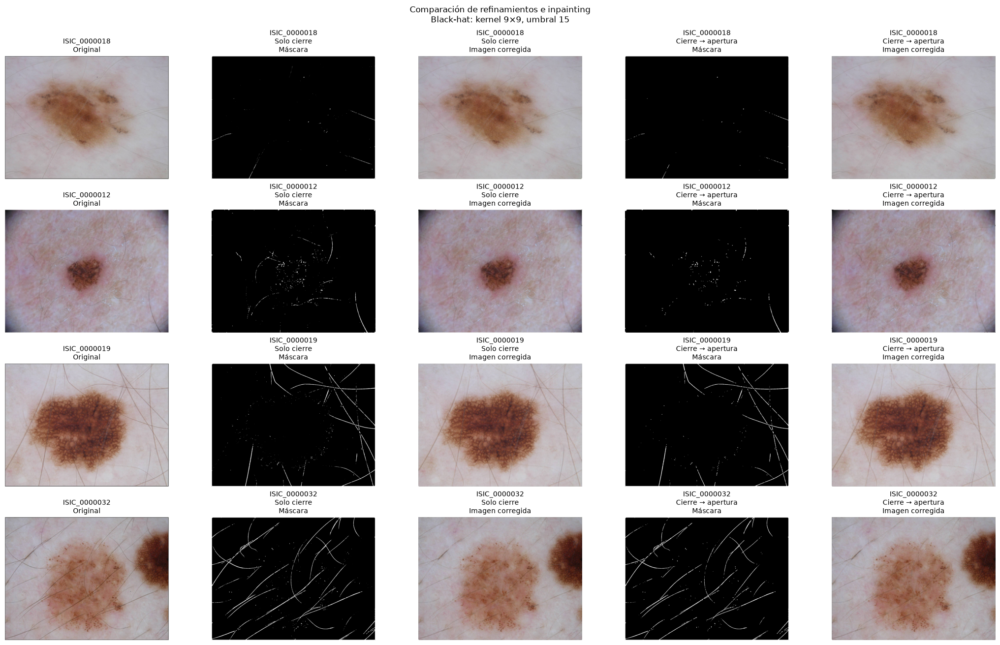

In [47]:
refinamientos = ["Solo cierre", "Cierre → apertura"]

imagenes_corregidas = {}
mascaras_correccion = {}

fig, axes = plt.subplots(
    len(imagenes_pelos), 5,
    figsize=(21, 13),
    constrained_layout=True
)
fig.suptitle(
    "Comparación de refinamientos e inpainting\n"
    "Black-hat: kernel 9×9, umbral 15"
)

for fila, (image_id, original) in enumerate(imagenes_pelos.items()):
    imagenes_corregidas[image_id] = {}
    mascaras_correccion[image_id] = {}

    paneles = [("Original", original)]

    for refinamiento in refinamientos:
        corregida, mascara = corregir_artefactos(
            original,
            tamanio_kernel=9,
            umbral=15,
            refinamiento=refinamiento
        )

        imagenes_corregidas[image_id][refinamiento] = corregida
        mascaras_correccion[image_id][refinamiento] = mascara

        paneles.extend([
            (f"{refinamiento}\nMáscara", mascara),
            (f"{refinamiento}\nImagen corregida", corregida),
        ])

    for columna, (nombre, resultado) in enumerate(paneles):
        ax = axes[fila, columna]

        if resultado.ndim == 2:
            ax.imshow(resultado, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(resultado)

        ax.set_title(f"{image_id}\n{nombre}", fontsize=10)
        ax.axis("off")

plt.show()

In [48]:
def artefactos_residuales(imagen_rgb, kernel, limite=15):
    """Porcentaje de píxeles con respuesta black-hat mayor al límite."""
    gris = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2GRAY)
    blackhat = cv2.morphologyEx(
        gris, cv2.MORPH_BLACKHAT, kernel
    )
    return 100 * (blackhat > limite).mean()

In [49]:
# Mismos parámetros para evaluar todas las variantes.
kernel_evaluacion = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (9, 9)
)
limite_evaluacion = 15

filas = []

for image_id, original in imagenes_pelos.items():
    antes = artefactos_residuales(
        original, kernel_evaluacion, limite_evaluacion
    )

    for metodo in ["Solo cierre", "Cierre → apertura"]:
        corregida = imagenes_corregidas[image_id][metodo]
        mascara = mascaras_correccion[image_id][metodo]

        despues = artefactos_residuales(
            corregida, kernel_evaluacion, limite_evaluacion
        )

        filas.append({
            "image_id": image_id,
            "Refinamiento": metodo,
            "% de píxeles en máscara": 100 * (mascara > 0).mean(),
            "Respuesta residual antes (%)": antes,
            "Respuesta residual después (%)": despues,
            "Reducción relativa (%)": (
                100 * (antes - despues) / antes
                if antes > 0 else np.nan
            ),
        })

evaluacion_artefactos = pd.DataFrame(filas)

display(evaluacion_artefactos.round(2))

,image_id,Refinamiento,% de píxeles en máscara,Respuesta residual antes (%),Respuesta residual después (%),Reducción relativa (%)
0,ISIC_0000018,Solo cierre,1.07,0.75,0.00,99.98
1,ISIC_0000018,Cierre → apertura,1.02,0.75,0.05,93.40
2,ISIC_0000012,Solo cierre,0.64,0.61,0.03,95.80
3,ISIC_0000012,Cierre → apertura,0.34,0.61,0.32,48.53
4,ISIC_0000019,Solo cierre,2.47,2.14,0.00,99.84
5,ISIC_0000019,Cierre → apertura,2.33,2.14,0.14,93.23
6,ISIC_0000032,Solo cierre,3.51,3.12,0.02,99.47
7,ISIC_0000032,Cierre → apertura,3.29,3.12,0.22,92.83


### Resultado de la corrección de artefactos

Se compararon los refinamientos mediante solo cierre y cierre seguido
de apertura, utilizando un black-hat con kernel de 9 × 9 píxeles,
umbral de 15 e inpainting con radio de 3 píxeles.

La apertura posterior al cierre elimina algunos pelos finos de las
máscaras, especialmente en ISIC_0000012. Se selecciona solo cierre
para continuar, ya que conserva más trazos y presenta una mayor
reducción de la respuesta black-hat en los cuatro ejemplos.

Con este refinamiento, las máscaras abarcan el 1,07 % de los píxeles
en ISIC_0000018, el 0,64 % en ISIC_0000012, el 2,47 % en
ISIC_0000019 y el 3,51 % en ISIC_0000032.

La proporción de píxeles con respuesta black-hat superior a 15
disminuye entre un 95,80 % y un 99,98 %. Este indicador utiliza el
mismo detector empleado para generar las máscaras: describe la
reducción de su respuesta, pero no representa el porcentaje de pelos
eliminados ni constituye una validación independiente.

Visualmente, la corrección es parcial y resulta más evidente en
ISIC_0000032. Persisten pelos y segmentos no detectados, especialmente
en ISIC_0000018 e ISIC_0000012. Además, las máscaras incluyen algunos
puntos dentro de las lesiones, por lo que el inpainting puede modificar
estructuras reales.

Se comparará la segmentación con y sin corrección sobre las 150 imágenes
mediante Dice e IoU para determinar si este preprocesamiento resulta
beneficioso. Las características de color y textura se calcularán sobre
las imágenes originales, dentro de las regiones seleccionadas, para
evitar incorporar valores estimados por el inpainting.

## Primera prueba de segmentación: efecto de la corrección de artefactos

Se comparan las imágenes sin corrección y con corrección mediante
black-hat de 9 × 9 píxeles, umbral de 15, cierre morfológico de 3 × 3
e inpainting. Se utilizan los mismos parámetros para las 150 imágenes.

Ambas alternativas se convierten a escala de grises y se procesan
con CLAHE. Luego se aplica Otsu con umbralización inversa para obtener
regiones oscuras candidatas a lesión.

Esta primera comparación mantiene fijo el tratamiento del contraste
para estudiar el efecto de la corrección de artefactos. Posteriormente
se compararán las alternativas de mejora de contraste.

Las máscaras obtenidas se evalúan mediante Dice e IoU respecto de las
máscaras de referencia. Estas últimas se utilizan exclusivamente para
la evaluación y no intervienen en la segmentación.

Se muestran máscaras y contornos de un ejemplo por diagnóstico.
En esta prueba todavía no se aplica limpieza morfológica ni selección
de componentes a las máscaras de Otsu.

In [50]:
def calcular_dice_iou(mascara, referencia):
    prediccion = mascara > 0
    verdad = referencia > 0

    if prediccion.shape != verdad.shape:
        raise ValueError("La predicción y la referencia tienen distinto tamaño.")

    interseccion = np.count_nonzero(prediccion & verdad)
    union = np.count_nonzero(prediccion | verdad)
    suma = np.count_nonzero(prediccion) + np.count_nonzero(verdad)

    dice = 2 * interseccion / suma if suma > 0 else 1.0
    iou = interseccion / union if union > 0 else 1.0

    return dice, iou

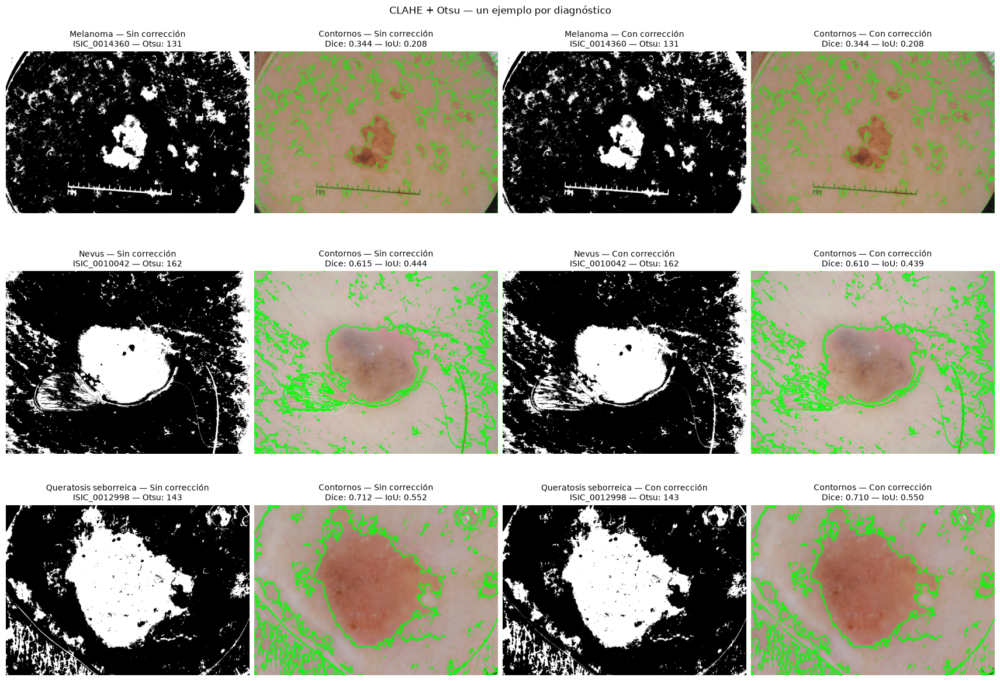

Cantidad  Dice_promedio  Dice_mediano  \
Diagnóstico           Variante                                                
Melanoma              Con corrección        50          0.548         0.573   
                      Sin corrección        50          0.549         0.571   
Nevus                 Con corrección        50          0.480         0.459   
                      Sin corrección        50          0.478         0.449   
Queratosis seborreica Con corrección        50          0.381         0.381   
                      Sin corrección        50          0.381         0.372   

                                      IoU_promedio  IoU_mediano  
Diagnóstico           Variante                                   
Melanoma              Con corrección         0.410        0.402  
                      Sin corrección         0.409        0.399  
Nevus                 Con corrección         0.345        0.298  
                      Sin corrección         0.341        0.289  
Queratosis seborreica Con corrección         0.258        0.235  
                      Sin corrección         0.258        0.229

In [51]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

filas_otsu = []
mascaras_otsu = {}
diagnosticos_mostrados = set()

fig, axes = plt.subplots(
    3, 4, figsize=(17, 12), constrained_layout=True
)

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))
    ruta_mascara = carpeta_mascaras / f"{image_id}_segmentation.png"
    referencia = cv2.imread(str(ruta_mascara), cv2.IMREAD_GRAYSCALE)

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    if referencia is None:
        raise FileNotFoundError(f"No se pudo leer la máscara: {ruta_mascara}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Generar la corrección para cada una de las 150 imágenes.
    corregida, _ = corregir_artefactos(
        original,
        tamanio_kernel=9,
        umbral=15,
        refinamiento="Solo cierre"
    )

    variantes = {
        "Sin corrección": original,
        "Con corrección": corregida,
    }

    mostrar = diagnostico not in diagnosticos_mostrados

    if mostrar:
        fila = len(diagnosticos_mostrados)
        mascaras_otsu[image_id] = {}

    for columna, (nombre, resultado) in enumerate(variantes.items()):
        gris = cv2.cvtColor(resultado, cv2.COLOR_RGB2GRAY)
        mejorada = clahe.apply(gris)

        umbral, mascara = cv2.threshold(
            mejorada, 0, 255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        dice, iou = calcular_dice_iou(mascara, referencia)

        filas_otsu.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Variante": nombre,
            "Umbral Otsu": umbral,
            "Dice": dice,
            "IoU": iou,
        })

        # Guardar y mostrar solamente los ejemplos visuales.
        if mostrar:
            mascaras_otsu[image_id][nombre] = mascara

            axes[fila, 2 * columna].imshow(
                mascara, cmap="gray", vmin=0, vmax=255
            )
            axes[fila, 2 * columna].set_title(
                f"{diagnostico} — {nombre}\n"
                f"{image_id} — Otsu: {umbral:.0f}",
                fontsize=10
            )

            contornos, _ = cv2.findContours(
                mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )

            superpuesta = original.copy()
            cv2.drawContours(
                superpuesta, contornos, -1, (0, 255, 0), 2
            )

            axes[fila, 2 * columna + 1].imshow(superpuesta)
            axes[fila, 2 * columna + 1].set_title(
                f"Contornos — {nombre}\n"
                f"Dice: {dice:.3f} — IoU: {iou:.3f}",
                fontsize=10
            )

    if mostrar:
        for ax in axes[fila]:
            ax.axis("off")
        diagnosticos_mostrados.add(diagnostico)

fig.suptitle("CLAHE + Otsu — un ejemplo por diagnóstico")
plt.show()

# Resultados individuales: 150 imágenes × 2 alternativas.
resultados_otsu = pd.DataFrame(filas_otsu)

resumen_otsu = resultados_otsu.groupby(
    ["Diagnóstico", "Variante"]
).agg(
    Cantidad=("image_id", "nunique"),
    Dice_promedio=("Dice", "mean"),
    Dice_mediano=("Dice", "median"),
    IoU_promedio=("IoU", "mean"),
    IoU_mediano=("IoU", "median"),
)

display(resumen_otsu.round(3))

### Observaciones de la primera prueba de segmentación

En los ejemplos mostrados, CLAHE seguido de Otsu produce máscaras
fragmentadas e incluye regiones externas a la lesión. La corrección
de artefactos no modifica el umbral seleccionado al redondearlo a
niveles enteros y genera cambios pequeños en las métricas.

En el ejemplo de melanoma, Dice permanece en 0,344; en nevus disminuye
de 0,615 a 0,610 y en queratosis seborreica de 0,712 a 0,710.
Por lo tanto, no se observa una mejora en estos tres casos.

Aunque algunos contornos siguen visualmente el borde de la lesión,
las máscaras también contienen numerosas regiones adicionales.
Estas selecciones externas contribuyen a reducir Dice e IoU.

Las observaciones corresponden únicamente a los ejemplos visualizados.
La conclusión sobre las 150 imágenes se establecerá a partir de la
tabla de resultados y de los cambios por imagen.

### Resultado de la primera prueba de segmentación

Se evaluó CLAHE seguido de Otsu sobre las 150 imágenes, comparando
las alternativas con y sin corrección de artefactos.

La corrección produce cambios pequeños en las métricas promedio.
En melanoma, Dice pasa de 0,549 a 0,548 e IoU de 0,409 a 0,410.
En nevus, Dice aumenta de 0,478 a 0,480 e IoU de 0,341 a 0,345.
En queratosis seborreica, los promedios permanecen en 0,381 para Dice
y 0,258 para IoU, a la precisión mostrada.

Las medianas presentan ligeros aumentos con la corrección, pero estos
resultados descriptivos no permiten afirmar una mejora consistente
ni estadísticamente significativa.

En los ejemplos visualizados, las máscaras incluyen regiones de piel,
marcas y otros artefactos, además de la lesión. Aunque algunos contornos
siguen su borde, la selección de regiones externas limita la concordancia
con las máscaras de referencia.

La corrección de artefactos, con los parámetros utilizados, no resuelve
las principales limitaciones de esta segmentación. A continuación se
comparará Otsu sin ecualización, con ecualización global y con CLAHE
para estudiar el efecto del tratamiento del contraste.

## Efecto del tratamiento del contraste sobre la segmentación por Otsu

Se comparan tres entradas para Otsu: escala de grises sin ecualizar,
ecualización global y CLAHE. Las tres parten de la misma imagen
corregida de artefactos y no incluyen suavizado adicional.

Se utilizan las 150 imágenes de la muestra balanceada y se mantienen
los mismos parámetros para todos los diagnósticos. Otsu se aplica
con umbralización inversa, considerando las regiones oscuras como
candidatas a lesión.

Las máscaras se evalúan mediante Dice e IoU respecto de las referencias.
En esta etapa no se aplica limpieza morfológica ni selección de
componentes, para estudiar primero el efecto del contraste.

Este análisis permite evaluar cómo una decisión de preprocesamiento
modifica la segmentación, en línea con el objetivo del anteproyecto.

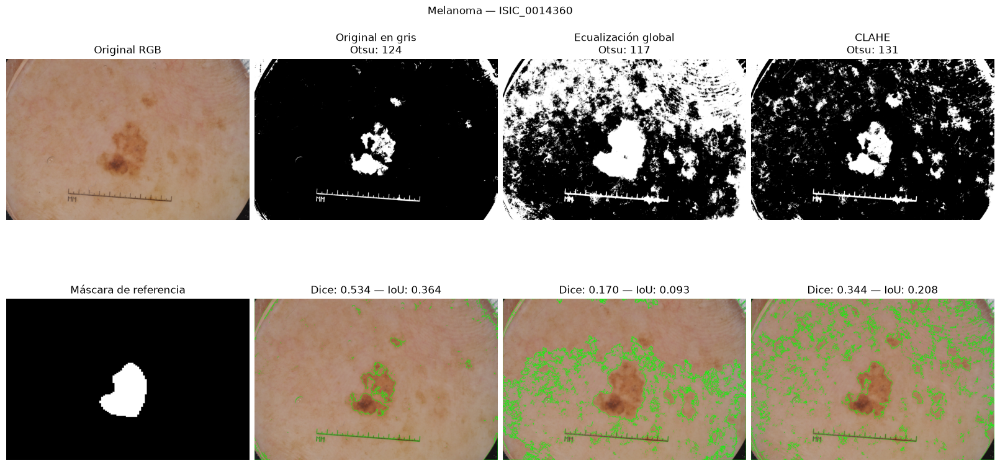

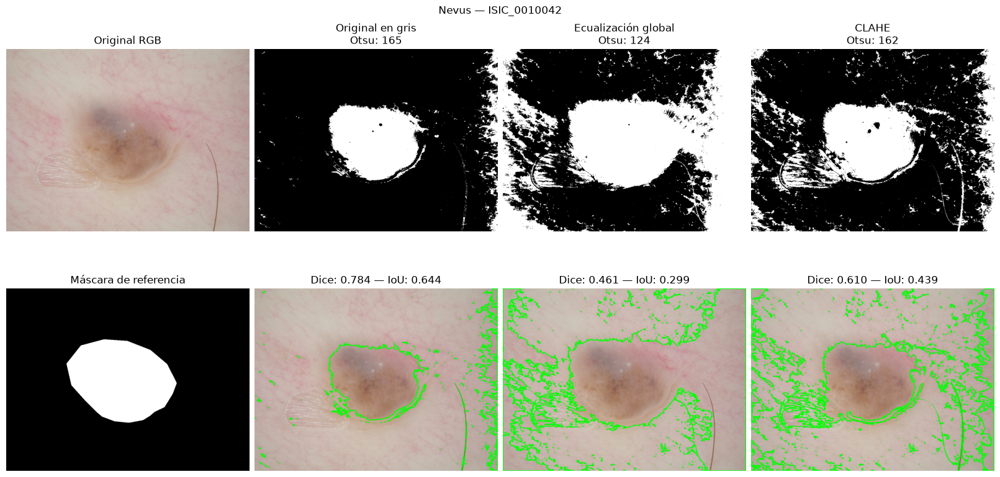

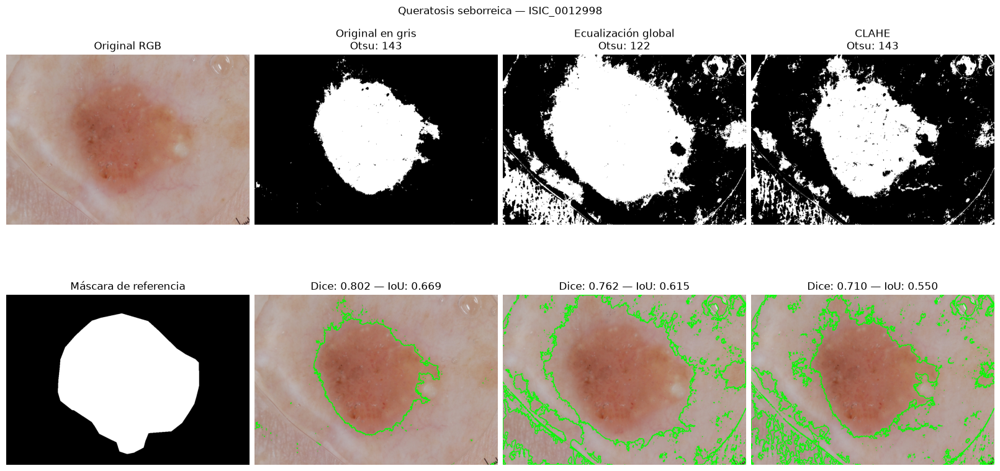

Cantidad  Dice_promedio  \
Diagnóstico           Contraste                                      
Melanoma              CLAHE                      50          0.548   
                      Ecualización global        50          0.497   
                      Original en gris           50          0.594   
Nevus                 CLAHE                      50          0.480   
                      Ecualización global        50          0.326   
                      Original en gris           50          0.515   
Queratosis seborreica CLAHE                      50          0.381   
                      Ecualización global        50          0.334   
                      Original en gris           50          0.413   

                                           Dice_mediano  IoU_promedio  \
Diagnóstico           Contraste                                         
Melanoma              CLAHE                       0.573         0.410   
                      Ecualización global         0.423         0.372   
                      Original en gris            0.690         0.475   
Nevus                 CLAHE                       0.459         0.345   
                      Ecualización global         0.280         0.215   
                      Original en gris            0.588         0.402   
Queratosis seborreica CLAHE                       0.381         0.258   
                      Ecualización global         0.315         0.220   
                      Original en gris            0.446         0.313   

                                           IoU_mediano  
Diagnóstico           Contraste                         
Melanoma              CLAHE                      0.402  
                      Ecualización global        0.268  
                      Original en gris           0.527  
Nevus                 CLAHE                      0.298  
                      Ecualización global        0.163  
                      Original en gris           0.416  
Queratosis seborreica CLAHE                      0.235  
                      Ecualización global        0.187  
                      Original en gris           0.287

In [52]:
filas_contraste_otsu = []
ejemplos_contraste_otsu = {}
diagnosticos_mostrados = set()

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))
    ruta_mascara = carpeta_mascaras / f"{image_id}_segmentation.png"
    referencia = cv2.imread(
        str(ruta_mascara), cv2.IMREAD_GRAYSCALE
    )

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    if referencia is None:
        raise FileNotFoundError(f"No se pudo leer: {ruta_mascara}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Mantener fija la corrección en las tres alternativas.
    corregida, _ = corregir_artefactos(
        original,
        tamanio_kernel=9,
        umbral=15,
        refinamiento="Solo cierre"
    )

    gris = cv2.cvtColor(corregida, cv2.COLOR_RGB2GRAY)
    variantes = aplicar_contraste(gris)

    mostrar = diagnostico not in diagnosticos_mostrados

    if mostrar:
        ejemplos_contraste_otsu[image_id] = {}

        # Original, referencia y resultados de las tres variantes.
        fig, axes = plt.subplots(
            2, 4, figsize=(16, 8), constrained_layout=True
        )
        fig.suptitle(f"{diagnostico} — {image_id}")

        axes[0, 0].imshow(original)
        axes[0, 0].set_title("Original RGB")

        axes[1, 0].imshow(
            referencia, cmap="gray", vmin=0, vmax=255
        )
        axes[1, 0].set_title("Máscara de referencia")

    for columna, (nombre, entrada) in enumerate(
        variantes.items(), start=1
    ):
        umbral, mascara = cv2.threshold(
            entrada, 0, 255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        dice, iou = calcular_dice_iou(mascara, referencia)

        filas_contraste_otsu.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Contraste": nombre,
            "Umbral Otsu": umbral,
            "Dice": dice,
            "IoU": iou,
        })

        if mostrar:
            ejemplos_contraste_otsu[image_id][nombre] = mascara

            # Arriba: máscara obtenida.
            axes[0, columna].imshow(
                mascara, cmap="gray", vmin=0, vmax=255
            )
            axes[0, columna].set_title(
                f"{nombre}\nOtsu: {umbral:.0f}"
            )

            # Abajo: contornos sobre la misma original.
            contornos, _ = cv2.findContours(
                mascara,
                cv2.RETR_EXTERNAL,
                cv2.CHAIN_APPROX_SIMPLE
            )

            superpuesta = original.copy()
            cv2.drawContours(
                superpuesta, contornos, -1, (0, 255, 0), 2
            )

            axes[1, columna].imshow(superpuesta)
            axes[1, columna].set_title(
                f"Dice: {dice:.3f} — IoU: {iou:.3f}"
            )

    if mostrar:
        for ax in axes.ravel():
            ax.axis("off")

        plt.show()
        diagnosticos_mostrados.add(diagnostico)

# Resultados de las 150 imágenes × 3 variantes.
resultados_contraste_otsu = pd.DataFrame(filas_contraste_otsu)

resumen_contraste_otsu = resultados_contraste_otsu.groupby(
    ["Diagnóstico", "Contraste"]
).agg(
    Cantidad=("image_id", "nunique"),
    Dice_promedio=("Dice", "mean"),
    Dice_mediano=("Dice", "median"),
    IoU_promedio=("IoU", "mean"),
    IoU_mediano=("IoU", "median"),
)

display(resumen_contraste_otsu.round(3))

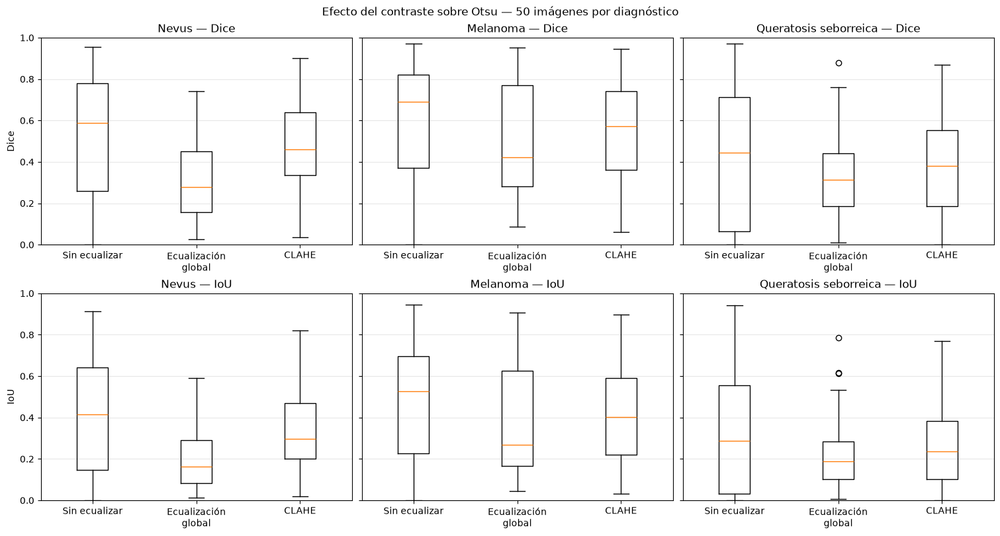

In [53]:
diagnosticos = ["Nevus", "Melanoma", "Queratosis seborreica"]
orden = ["Original en gris", "Ecualización global", "CLAHE"]
etiquetas = ["Sin ecualizar", "Ecualización\nglobal", "CLAHE"]

fig, axes = plt.subplots(
    2, 3, figsize=(15, 8), sharey="row",
    constrained_layout=True
)

for columna, diagnostico in enumerate(diagnosticos):
    datos = resultados_contraste_otsu[
        resultados_contraste_otsu["Diagnóstico"] == diagnostico
    ]

    for fila, metrica in enumerate(["Dice", "IoU"]):
        valores = [
            datos.loc[datos["Contraste"] == variante, metrica]
            for variante in orden
        ]

        ax = axes[fila, columna]
        ax.boxplot(valores)
        ax.set_xticks([1, 2, 3])
        ax.set_xticklabels(etiquetas)
        ax.set_ylim(0, 1)
        ax.set_title(f"{diagnostico} — {metrica}")
        ax.grid(axis="y", alpha=0.3)

        if columna == 0:
            ax.set_ylabel(metrica)

fig.suptitle(
    "Efecto del contraste sobre Otsu — 50 imágenes por diagnóstico"
)
plt.show()

### Resultado del efecto del contraste sobre Otsu

En las 150 imágenes evaluadas, la entrada en escala de grises sin
ecualizar presenta las mayores medianas de Dice e IoU en los tres
diagnósticos. CLAHE obtiene medianas intermedias y la ecualización
global presenta las menores.

Existe una dispersión amplia y superposición entre las distribuciones.
Por lo tanto, la ventaja observada es descriptiva y no implica que
una misma alternativa sea superior en todas las imágenes.

En los tres ejemplos visualizados, la variante sin ecualizar también
alcanza la mayor concordancia con la referencia. Sus valores de Dice
son 0,534 para melanoma, 0,784 para nevus y 0,802 para queratosis
seborreica. La ecualización global y CLAHE incorporan numerosas
regiones externas a la lesión, en concordancia con el realce de
textura y artefactos observado previamente.

Se selecciona la escala de grises sin ecualizar como entrada para
continuar las pruebas con Otsu. Esta variante parte de las imágenes
corregidas de artefactos y todavía presenta regiones adicionales,
fragmentación y diferencias respecto de los contornos de referencia.

A continuación se evaluará el refinamiento de las máscaras mediante
operaciones morfológicas y selección de componentes. Las máscaras
de referencia se utilizarán únicamente para evaluar los resultados.

In [65]:
def refinar_mascara_otsu(mascara):
    kernel_apertura = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )
    kernel_cierre = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (9, 9)
    )

    cierre = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel_cierre
    )
    morfologica = cv2.morphologyEx(
        cierre, cv2.MORPH_OPEN, kernel_apertura
    )

    cantidad, etiquetas, propiedades, _ = (
        cv2.connectedComponentsWithStats(
            morfologica, connectivity=8
        )
    )

    seleccionada = np.zeros_like(mascara)

    if cantidad <= 1:
        return morfologica, seleccionada

    areas = propiedades[:, cv2.CC_STAT_AREA]
    mayor = 1 + np.argmax(areas[1:])
    componente_mayor = etiquetas == mayor

    # Distancia de cada píxel al componente mayor.
    distancias = cv2.distanceTransform(
        (~componente_mayor).astype(np.uint8),
        cv2.DIST_L2, cv2.DIST_MASK_PRECISE
    )

    # Criterios iniciales iguales para todas las imágenes.
    distancia_maxima = 0.03 * min(mascara.shape)
    area_minima = 0.10 * areas[mayor]

    seleccionada[componente_mayor] = 255

    for etiqueta in range(1, cantidad):
        if etiqueta == mayor or areas[etiqueta] < area_minima:
            continue

        componente = etiquetas == etiqueta

        if distancias[componente].min() <= distancia_maxima:
            seleccionada[componente] = 255

    return morfologica, seleccionada

In [58]:
def rellenar_huecos(mascara):
    # Agregar un borde negro para asegurar un fondo exterior conectado.
    ampliada = cv2.copyMakeBorder(
        mascara, 1, 1, 1, 1,
        cv2.BORDER_CONSTANT, value=0
    )

    # Pintar de blanco el fondo conectado al exterior.
    fondo = ampliada.copy()
    cv2.floodFill(fondo, None, (0, 0), 255)

    # Al invertir quedan blancos solo los huecos encerrados.
    huecos = cv2.bitwise_not(fondo)

    # Incorporar los huecos a la máscara y quitar el borde agregado.
    rellena = cv2.bitwise_or(ampliada, huecos)

    return rellena[1:-1, 1:-1]

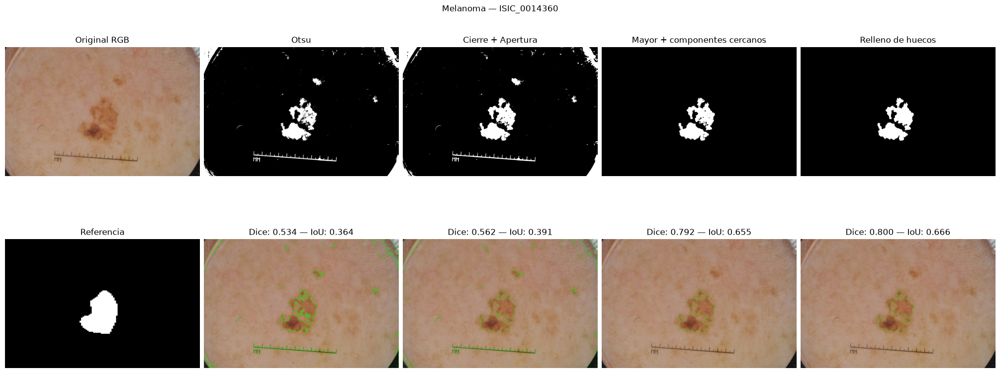

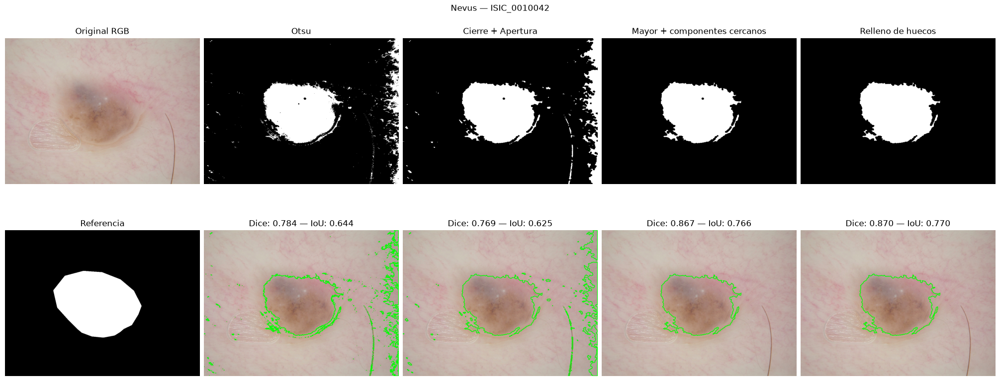

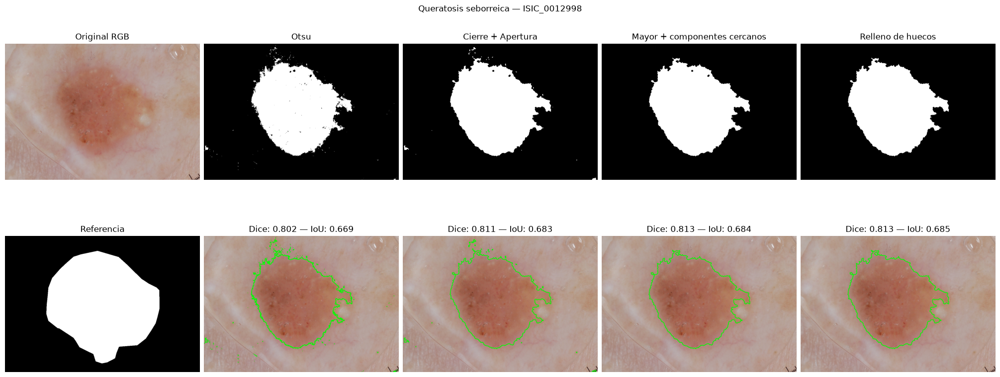

Cantidad  Dice_promedio  \
Diagnóstico           Etapa                                                   
Melanoma              Cierre + Apertura                   50          0.604   
                      Mayor + componentes cercanos        50          0.631   
                      Otsu                                50          0.594   
                      Relleno de huecos                   50          0.632   
Nevus                 Cierre + Apertura                   50          0.517   
                      Mayor + componentes cercanos        50          0.511   
                      Otsu                                50          0.515   
                      Relleno de huecos                   50          0.503   
Queratosis seborreica Cierre + Apertura                   50          0.414   
                      Mayor + componentes cercanos        50          0.455   
                      Otsu                                50          0.413   
                      Relleno de huecos                   50          0.449   

                                                    Dice_mediano  \
Diagnóstico           Etapa                                        
Melanoma              Cierre + Apertura                    0.709   
                      Mayor + componentes cercanos         0.800   
                      Otsu                                 0.690   
                      Relleno de huecos                    0.811   
Nevus                 Cierre + Apertura                    0.583   
                      Mayor + componentes cercanos         0.652   
                      Otsu                                 0.588   
                      Relleno de huecos                    0.652   
Queratosis seborreica Cierre + Apertura                    0.434   
                      Mayor + componentes cercanos         0.444   
                      Otsu                                 0.446   
                      Relleno de huecos                    0.409   

                                                    IoU_promedio  IoU_mediano  
Diagnóstico           Etapa                                                    
Melanoma              Cierre + Apertura                    0.487        0.550  
                      Mayor + componentes cercanos         0.540        0.667  
                      Otsu                                 0.475        0.527  
                      Relleno de huecos                    0.545        0.682  
Nevus                 Cierre + Apertura                    0.404        0.412  
                      Mayor + componentes cercanos         0.439        0.484  
                      Otsu                                 0.402        0.416  
                      Relleno de huecos                    0.434        0.484  
Queratosis seborreica Cierre + Apertura                    0.315        0.277  
                      Mayor + componentes cercanos         0.382        0.285  
                      Otsu                                 0.313        0.287  
                      Relleno de huecos                    0.376        0.257

In [ ]:
filas_refinamiento = []
ejemplos_refinamiento = {}
diagnosticos_mostrados = set()

for _, registro in df_muestra.iterrows():
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen = cv2.imread(str(rutas[image_id]))
    ruta_mascara = carpeta_mascaras / f"{image_id}_segmentation.png"
    referencia = cv2.imread(
        str(ruta_mascara), cv2.IMREAD_GRAYSCALE
    )

    if imagen is None:
        raise ValueError(f"No se pudo leer la imagen: {image_id}")

    if referencia is None:
        raise FileNotFoundError(f"No se pudo leer: {ruta_mascara}")

    original = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    corregida, _ = corregir_artefactos(
        original,
        tamanio_kernel=9,
        umbral=15,
        refinamiento="Solo cierre"
    )

    gris = cv2.cvtColor(corregida, cv2.COLOR_RGB2GRAY)

    _, mascara_otsu = cv2.threshold(
        gris, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    morfologica, seleccionada = refinar_mascara_otsu(
        mascara_otsu
    )

    rellena = rellenar_huecos(seleccionada)

    variantes = {
    "Otsu": mascara_otsu,
    "Cierre + Apertura": morfologica,
    "Mayor + componentes cercanos": seleccionada,
    "Relleno de huecos": rellena,
    }

    mostrar = diagnostico not in diagnosticos_mostrados

    if mostrar:
        ejemplos_refinamiento[image_id] = variantes

        fig, axes = plt.subplots(
            2, 5, figsize=(20, 8), constrained_layout=True
        )
        fig.suptitle(f"{diagnostico} — {image_id}")

        axes[0, 0].imshow(original)
        axes[0, 0].set_title("Original RGB")

        axes[1, 0].imshow(
            referencia, cmap="gray", vmin=0, vmax=255
        )
        axes[1, 0].set_title("Referencia")

    for columna, (nombre, mascara) in enumerate(
        variantes.items(), start=1
    ):
        dice, iou = calcular_dice_iou(mascara, referencia)

        filas_refinamiento.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Etapa": nombre,
            "Dice": dice,
            "IoU": iou,
        })

        if mostrar:
            axes[0, columna].imshow(
                mascara, cmap="gray", vmin=0, vmax=255
            )
            axes[0, columna].set_title(nombre)

            contornos, _ = cv2.findContours(
                mascara,
                cv2.RETR_EXTERNAL,
                cv2.CHAIN_APPROX_SIMPLE
            )

            superpuesta = original.copy()
            cv2.drawContours(
                superpuesta, contornos, -1, (0, 255, 0), 2
            )

            axes[1, columna].imshow(superpuesta)
            axes[1, columna].set_title(
                f"Dice: {dice:.3f} — IoU: {iou:.3f}"
            )

    if mostrar:
        for ax in axes.ravel():
            ax.axis("off")
        plt.show()
        diagnosticos_mostrados.add(diagnostico)

resultados_refinamiento = pd.DataFrame(filas_refinamiento)

resumen_refinamiento = resultados_refinamiento.groupby(
    ["Diagnóstico", "Etapa"]
).agg(
    Dice_promedio=("Dice", "mean"),
    Dice_mediano=("Dice", "median"),
    IoU_promedio=("IoU", "mean"),
    IoU_mediano=("IoU", "median"),
)

display(resumen_refinamiento.round(3))

## Segmentación mediante contornos activos: Chan–Vese

Se evalúa Chan–Vese morfológico como alternativa a la umbralización de Otsu. Este método ajusta iterativamente una región buscando diferenciar las intensidades de su interior y exterior, por lo que puede resultar útil cuando los bordes de la lesión son poco definidos.

Se utilizan las mismas 150 imágenes, con corrección de artefactos y conversión a escala de grises, sin ecualización. Para reducir el tiempo de procesamiento, se conserva la proporción de cada imagen y se limita su lado mayor a 512 píxeles, tanto para Otsu como para Chan–Vese.

El contorno se inicializa mediante una elipse central, bajo el supuesto de que la lesión se encuentra mayormente en esa zona. Se realizan 150 iteraciones, con un parámetro de suavizado de 2 y pesos iguales para las regiones interior y exterior. Estos parámetros se mantienen constantes para todas las imágenes.

Se comparan tres alternativas:

- **Otsu:** máscara obtenida mediante umbralización inversa.
- **Otsu refinado:** cierre, apertura y selección de la componente mayor junto con componentes cercanos.
- **Chan–Vese:** máscara obtenida mediante contornos activos, sin refinamiento posterior.

Las máscaras se llevan al tamaño original y se evalúan mediante **Dice e IoU** respecto de las máscaras de referencia, utilizadas exclusivamente para la evaluación. Además, se inspeccionan los contornos superpuestos sobre las imágenes originales para identificar fragmentación, inclusión de piel y pérdida de regiones de la lesión.

Como esta prueba incorpora un cambio de resolución, los resultados se comparan entre las alternativas de este bloque y pueden diferir de los obtenidos anteriormente.

In [68]:
def segmentar_chan_vese(gris, iteraciones=150, suavizado=2):
    """
    Aplica Chan–Vese morfológico sobre una imagen en gris.
    La inicialización es una elipse central, sin usar la referencia.
    Devuelve una máscara binaria de valores 0 y 255.
    """
    alto, ancho = gris.shape
    y, x = np.ogrid[:alto, :ancho]

    # Semiejes del 30 % del alto y del ancho.
    inicial = (
        ((y - (alto - 1) / 2) / (0.30 * alto)) ** 2
        + ((x - (ancho - 1) / 2) / (0.30 * ancho)) ** 2
        <= 1
    )

    resultado = morphological_chan_vese(
        gris.astype(np.float32) / 255.0,
        num_iter=iteraciones,
        init_level_set=inicial,
        smoothing=suavizado,
        lambda1=1,
        lambda2=1,
    )

    return resultado.astype(np.uint8) * 255

In [71]:
lado_maximo = 512

# Seleccionar 10 imágenes por diagnóstico de la muestra original.
df_prueba_contornos = (
    df_muestra.groupby("diagnostico", group_keys=False)
    .sample(n=10, random_state=42)
    .reset_index(drop=True)
)

filas_contornos = []
ejemplos_contornos = {}

# Un ejemplo visual por diagnóstico dentro de las 30 seleccionadas.
ids_ejemplo = set(
    df_prueba_contornos.groupby("diagnostico", sort=False)
    .head(1)["image_id"]
)

for numero, (_, registro) in enumerate(
    df_prueba_contornos.iterrows(), start=1
):
    image_id = registro["image_id"]
    diagnostico = registro["diagnostico"]

    imagen_bgr = cv2.imread(str(rutas[image_id]))
    referencia = cv2.imread(
        str(carpeta_mascaras / f"{image_id}_segmentation.png"),
        cv2.IMREAD_GRAYSCALE
    )

    if imagen_bgr is None or referencia is None:
        raise ValueError(
            f"No se pudo leer la imagen o referencia: {image_id}"
        )

    original = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)
    alto, ancho = original.shape[:2]

    if referencia.shape != (alto, ancho):
        raise ValueError(f"Tamaños incompatibles en {image_id}")

    # Mismo preprocesamiento para todas las alternativas.
    corregida, _ = corregir_artefactos(
        original,
        tamanio_kernel=9,
        umbral=15,
        refinamiento="Solo cierre"
    )
    gris = cv2.cvtColor(corregida, cv2.COLOR_RGB2GRAY)

    escala = min(1.0, lado_maximo / max(alto, ancho))
    nuevo_ancho = max(1, round(ancho * escala))
    nuevo_alto = max(1, round(alto * escala))

    gris_trabajo = cv2.resize(
        gris,
        (nuevo_ancho, nuevo_alto),
        interpolation=cv2.INTER_AREA
    )

    # Alternativa 1: Otsu sin refinamiento.
    _, mascara_otsu = cv2.threshold(
        gris_trabajo, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Alternativa 2: Otsu con el refinamiento anterior.
    _, mascara_refinada = refinar_mascara_otsu(mascara_otsu)

    # Alternativa 3: contornos activos.
    mascara_cv = segmentar_chan_vese(
        gris_trabajo,
        iteraciones=150,
        suavizado=2
    )

    # Refinamientos sobre Chan–Vese, a la resolución de trabajo.
    kernel_cv = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    mascara_cv_erosion = cv2.erode(
        mascara_cv, kernel_cv, iterations=1
    )

    mascara_cv_apertura = cv2.morphologyEx(
        mascara_cv, cv2.MORPH_OPEN, kernel_cv
    )

    variantes = {
        "Otsu": mascara_otsu,
        "Otsu refinado": mascara_refinada,
        "Chan–Vese": mascara_cv,
        "Chan–Vese + erosión": mascara_cv_erosion,
        "Chan–Vese + apertura": mascara_cv_apertura,
    }

    mascaras_originales = {}

    for metodo, mascara in variantes.items():
        # Recuperar el tamaño original conservando la máscara binaria.
        mascara_original = cv2.resize(
            mascara,
            (ancho, alto),
            interpolation=cv2.INTER_NEAREST
        )

        dice, iou = calcular_dice_iou(
            mascara_original, referencia
        )

        filas_contornos.append({
            "image_id": image_id,
            "Diagnóstico": diagnostico,
            "Método": metodo,
            "Dice": dice,
            "IoU": iou,
        })

        mascaras_originales[metodo] = mascara_original

    # Guardar un ejemplo por diagnóstico para las figuras.
    if image_id in ids_ejemplo:
        ejemplos_contornos[image_id] = {
            "Diagnóstico": diagnostico,
            "Original": original,
            "Referencia": referencia,
            "Máscaras": mascaras_originales,
        }

    if numero % 5 == 0 or numero == len(df_prueba_contornos):
        print(
            f"Procesadas {numero}/{len(df_prueba_contornos)} imágenes",
            flush=True
        )

resultados_contornos = pd.DataFrame(filas_contornos)

resumen_contornos = resultados_contornos.groupby(
    ["Diagnóstico", "Método"]
).agg(
    Cantidad=("image_id", "nunique"),
    Dice_promedio=("Dice", "mean"),
    Dice_mediano=("Dice", "median"),
    IoU_promedio=("IoU", "mean"),
    IoU_mediano=("IoU", "median"),
)

display(resumen_contornos.round(3))

Procesadas 5/30 imágenes
Procesadas 10/30 imágenes
Procesadas 15/30 imágenes
Procesadas 20/30 imágenes
Procesadas 25/30 imágenes
Procesadas 30/30 imágenes


Cantidad  Dice_promedio  \
Diagnóstico           Método                                          
Melanoma              Chan–Vese                   10          0.733   
                      Chan–Vese + apertura        10          0.733   
                      Chan–Vese + erosión         10          0.728   
                      Otsu                        10          0.587   
                      Otsu refinado               10          0.576   
Nevus                 Chan–Vese                   10          0.705   
                      Chan–Vese + apertura        10          0.705   
                      Chan–Vese + erosión         10          0.693   
                      Otsu                        10          0.500   
                      Otsu refinado               10          0.510   
Queratosis seborreica Chan–Vese                   10          0.627   
                      Chan–Vese + apertura        10          0.627   
                      Chan–Vese + erosión         10          0.625   
                      Otsu                        10          0.490   
                      Otsu refinado               10          0.544   

                                            Dice_mediano  IoU_promedio  \
Diagnóstico           Método                                             
Melanoma              Chan–Vese                    0.865         0.630   
                      Chan–Vese + apertura         0.865         0.630   
                      Chan–Vese + erosión          0.856         0.622   
                      Otsu                         0.722         0.490   
                      Otsu refinado                0.839         0.510   
Nevus                 Chan–Vese                    0.846         0.611   
                      Chan–Vese + apertura         0.846         0.611   
                      Chan–Vese + erosión          0.827         0.593   
                      Otsu                         0.554         0.398   
                      Otsu refinado                0.619         0.434   
Queratosis seborreica Chan–Vese                    0.732         0.524   
                      Chan–Vese + apertura         0.732         0.524   
                      Chan–Vese + erosión          0.733         0.520   
                      Otsu                         0.446         0.382   
                      Otsu refinado                0.563         0.455   

                                            IoU_mediano  
Diagnóstico           Método                             
Melanoma              Chan–Vese                   0.763  
                      Chan–Vese + apertura        0.763  
                      Chan–Vese + erosión         0.748  
                      Otsu                        0.568  
                      Otsu refinado               0.722  
Nevus                 Chan–Vese                   0.733  
                      Chan–Vese + apertura        0.733  
                      Chan–Vese + erosión         0.706  
                      Otsu                        0.385  
                      Otsu refinado               0.460  
Queratosis seborreica Chan–Vese                   0.580  
                      Chan–Vese + apertura        0.580  
                      Chan–Vese + erosión         0.579  
                      Otsu                        0.287  
                      Otsu refinado               0.406

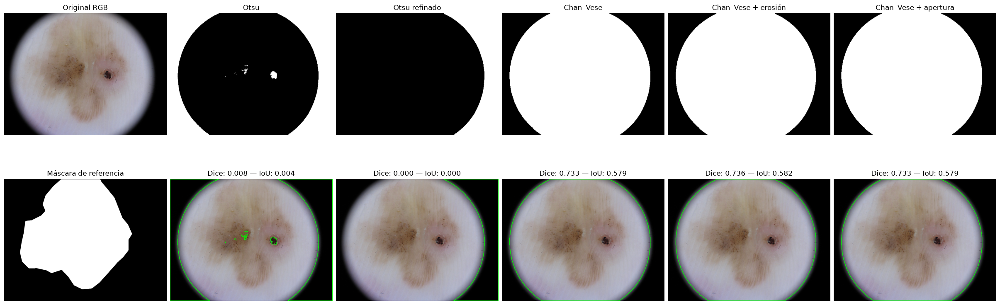

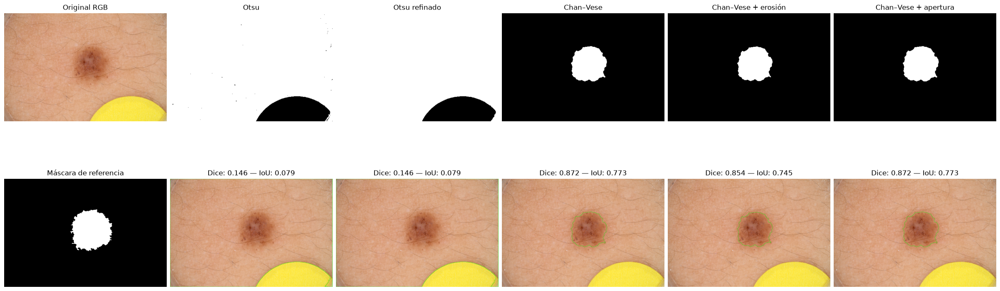

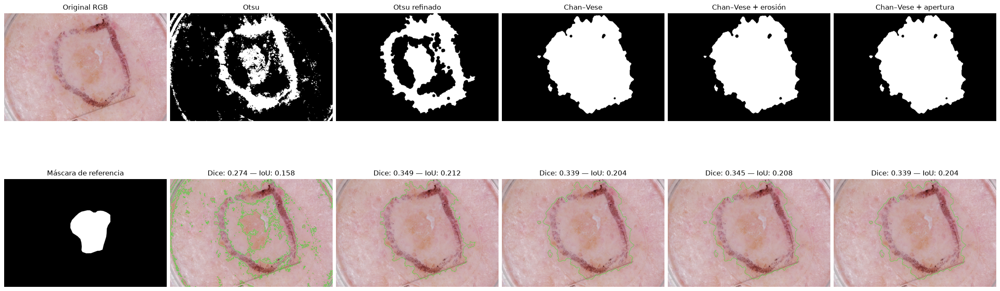

In [73]:
for image_id, ejemplo in ejemplos_contornos.items():
    original = ejemplo["Original"]
    referencia = ejemplo["Referencia"]

    cantidad_columnas = 1 + len(ejemplo["Máscaras"])

    fig, axes = plt.subplots(
        2, cantidad_columnas,
        figsize=(4 * cantidad_columnas, 8),
        constrained_layout=True
    )

    axes[0, 0].imshow(original)
    axes[0, 0].set_title("Original RGB")

    axes[1, 0].imshow(
        referencia, cmap="gray", vmin=0, vmax=255
    )
    axes[1, 0].set_title("Máscara de referencia")

    for columna, (metodo, mascara) in enumerate(
        ejemplo["Máscaras"].items(), start=1
    ):
        axes[0, columna].imshow(
            mascara, cmap="gray", vmin=0, vmax=255
        )
        axes[0, columna].set_title(metodo)

        contornos, _ = cv2.findContours(
            mascara,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        superpuesta = original.copy()
        cv2.drawContours(
            superpuesta, contornos, -1, (0, 255, 0), 2
        )

        dice, iou = calcular_dice_iou(mascara, referencia)

        axes[1, columna].imshow(superpuesta)
        axes[1, columna].set_title(
            f"Dice: {dice:.3f} — IoU: {iou:.3f}"
        )

    for ax in axes.flat:
        ax.axis("off")

    plt.show()